In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv.csv")

In [3]:
df.head()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [14]:
df.tail()

,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
1995,B_1131,I_047,C_17,0.589309,19.227979,46.242023,0.433437,0.848756,0.641781,0.261656,4.339478,0.643116
1996,B_1295,I_037,C_25,0.980000,36.737265,93.249093,0.103561,1.000000,0.688175,0.375195,4.912936,0.959988
1997,B_0861,I_033,C_06,0.531447,24.907878,83.990693,0.512266,0.918924,0.598276,0.271701,4.211113,0.773437
1998,B_1460,I_069,C_10,0.641025,22.395362,80.044231,0.317231,0.558183,0.575629,0.135500,4.182141,0.962627
1999,B_1127,I_045,C_22,0.300000,23.101794,86.891153,0.700000,0.563834,0.538691,0.210189,4.420309,0.545611


In [5]:
df.columns

Index(['batch_id', 'instructor_id', 'course_id', 'completion_rate',
       'avg_score_improvement', 'avg_quiz_score', 'dropout_rate',
       'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate',
       'avg_feedback_score', 'feedback_response_rate'],
      dtype='object')

In [6]:
df.shape

(2000, 12)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   batch_id                    2000 non-null   object 
 1   instructor_id               2000 non-null   object 
 2   course_id                   2000 non-null   object 
 3   completion_rate             2000 non-null   float64
 4   avg_score_improvement       2000 non-null   float64
 5   avg_quiz_score              2000 non-null   float64
 6   dropout_rate                2000 non-null   float64
 7   avg_watch_time              2000 non-null   float64
 8   assignment_submission_rate  2000 non-null   float64
 9   forum_activity_rate         2000 non-null   float64
 10  avg_feedback_score          2000 non-null   float64
 11  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(3)
memory usage: 187.6+ KB


In [8]:
df.describe()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


In [10]:
df.isnull().sum()

batch_id                      0
instructor_id                 0
course_id                     0
completion_rate               0
avg_score_improvement         0
avg_quiz_score                0
dropout_rate                  0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [17]:
print("unique batch id:",df['batch_id'].nunique())

unique batch id: 2000


In [18]:
print("unique instructor id:",df['instructor_id'].nunique())

unique instructor id: 120


In [19]:
print("unique course id:",df['course_id'].nunique())

unique course id: 25


### Make instructor id first column because our main purpose is to find out instructor effectiveness

In [20]:
df=df[['instructor_id','course_id','batch_id']+[col for col in df.columns if col not in['instructor_id','course_id','batch_id']]]

In [21]:
df.head()

,instructor_id,course_id,batch_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_044,C_01,B_1861,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,I_119,C_06,B_0354,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,I_050,C_03,B_1334,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,I_024,C_21,B_0906,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,I_001,C_08,B_1290,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


### sort instructor id followed by course id followed by batch id so that interpretation will become easy to understand

In [22]:
df=df.sort_values(by=['instructor_id','course_id','batch_id']).reset_index(drop=True)

In [23]:
df.head(10)

,instructor_id,course_id,batch_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,C_01,B_0329,0.650412,30.381328,85.387071,0.345120,0.699440,0.650831,0.251056,4.282333,0.630174
1,I_001,C_01,B_0583,0.471923,21.862832,80.479115,0.578279,0.905515,0.748359,0.348554,4.727822,0.884316
2,I_001,C_03,B_1840,0.513849,27.281641,76.333152,0.522611,0.790523,0.933166,0.181691,3.929714,0.869538
3,I_001,C_04,B_0280,0.425241,25.928073,70.306925,0.579022,0.781238,0.820817,0.301590,4.594004,0.625152
4,I_001,C_05,B_1607,0.474798,37.252912,90.405124,0.520068,0.709533,0.605071,0.370148,3.735890,0.651008
5,I_001,C_08,B_0852,0.565452,26.112106,66.462439,0.452029,0.989726,0.783941,0.258833,4.846461,1.000000
6,I_001,C_08,B_0890,0.652089,36.883153,85.450761,0.399007,0.904490,0.507565,0.394126,4.789839,0.571586
7,I_001,C_08,B_0999,0.530849,26.176315,79.885382,0.458035,0.705166,0.727205,0.182105,4.028166,0.413349
8,I_001,C_08,B_1143,0.545357,19.189788,90.587862,0.507008,0.733658,0.745207,0.000000,4.602515,0.655761
9,I_001,C_08,B_1290,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [27]:
df.head(30)

,instructor_id,course_id,batch_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,C_01,B_0329,0.650412,30.381328,85.387071,0.345120,0.699440,0.650831,0.251056,4.282333,0.630174
1,I_001,C_01,B_0583,0.471923,21.862832,80.479115,0.578279,0.905515,0.748359,0.348554,4.727822,0.884316
2,I_001,C_03,B_1840,0.513849,27.281641,76.333152,0.522611,0.790523,0.933166,0.181691,3.929714,0.869538
3,I_001,C_04,B_0280,0.425241,25.928073,70.306925,0.579022,0.781238,0.820817,0.301590,4.594004,0.625152
4,I_001,C_05,B_1607,0.474798,37.252912,90.405124,0.520068,0.709533,0.605071,0.370148,3.735890,0.651008
5,I_001,C_08,B_0852,0.565452,26.112106,66.462439,0.452029,0.989726,0.783941,0.258833,4.846461,1.000000
6,I_001,C_08,B_0890,0.652089,36.883153,85.450761,0.399007,0.904490,0.507565,0.394126,4.789839,0.571586
7,I_001,C_08,B_0999,0.530849,26.176315,79.885382,0.458035,0.705166,0.727205,0.182105,4.028166,0.413349
8,I_001,C_08,B_1143,0.545357,19.189788,90.587862,0.507008,0.733658,0.745207,0.000000,4.602515,0.655761
9,I_001,C_08,B_1290,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


In [28]:
df=df.round(4)

In [29]:
df.head()

,instructor_id,course_id,batch_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,I_001,C_01,B_0329,0.6504,30.3813,85.3871,0.3451,0.6994,0.6508,0.2511,4.2823,0.6302
1,I_001,C_01,B_0583,0.4719,21.8628,80.4791,0.5783,0.9055,0.7484,0.3486,4.7278,0.8843
2,I_001,C_03,B_1840,0.5138,27.2816,76.3332,0.5226,0.7905,0.9332,0.1817,3.9297,0.8695
3,I_001,C_04,B_0280,0.4252,25.9281,70.3069,0.5790,0.7812,0.8208,0.3016,4.5940,0.6252
4,I_001,C_05,B_1607,0.4748,37.2529,90.4051,0.5201,0.7095,0.6051,0.3701,3.7359,0.6510


In [36]:
numerical_cols = df.select_dtypes(include=['int64','float64']).columns
categorical_cols = df.select_dtypes(include=['object','string']).columns

print("numerical cols:",list(numerical_cols))
print()
print("categorical cols:",list(categorical_cols))

numerical cols: ['completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'dropout_rate', 'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate']

categorical cols: ['instructor_id', 'course_id', 'batch_id']


In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

### shows the complete distribution of all the features

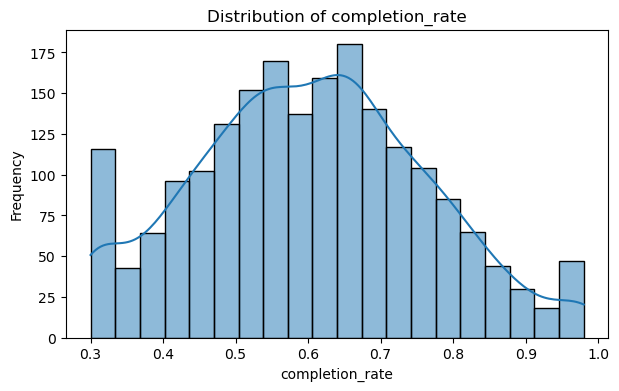

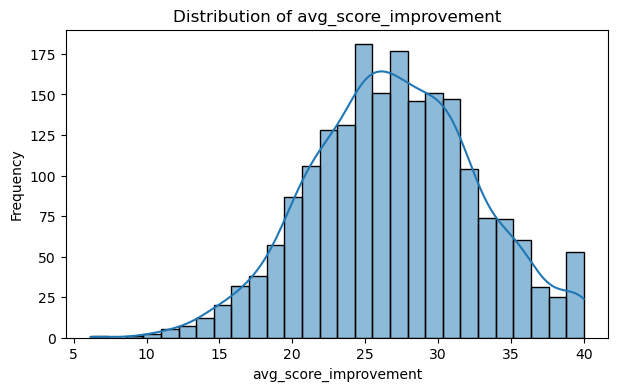

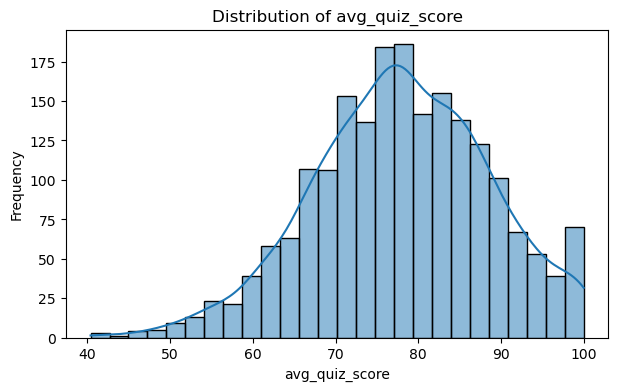

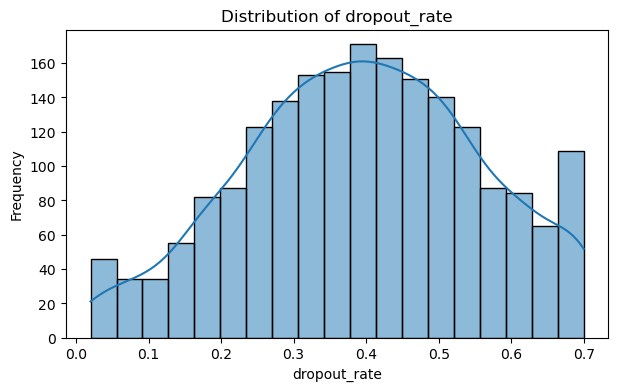

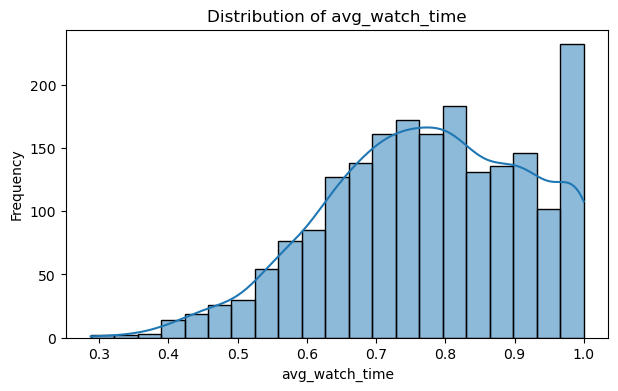

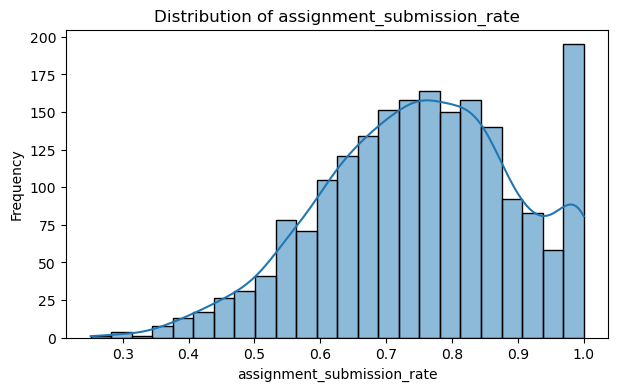

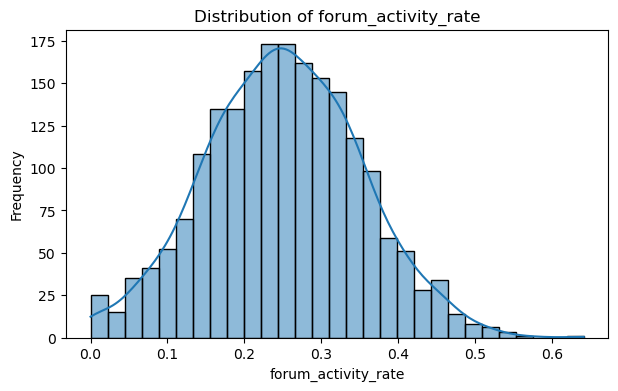

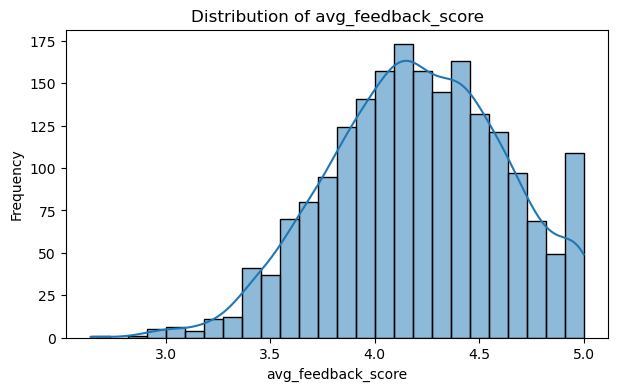

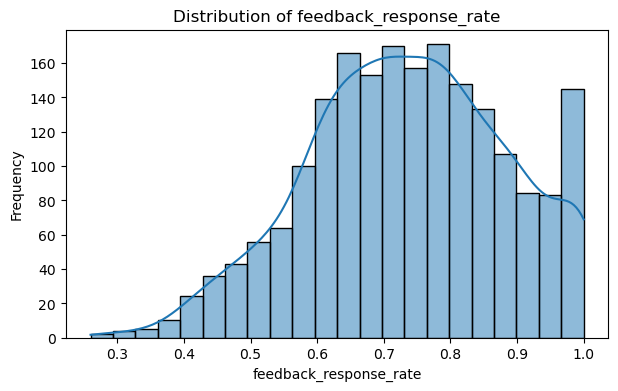

In [38]:
for col in numerical_cols:
    plt.figure(figsize=(7,4))
    sns.histplot(data=df,x=col,kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

### Boxplot helps to find out outliers and anomalies from the data

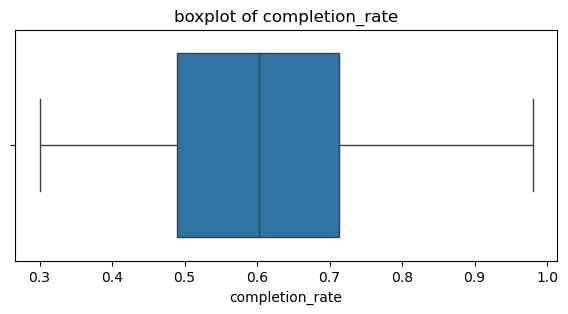

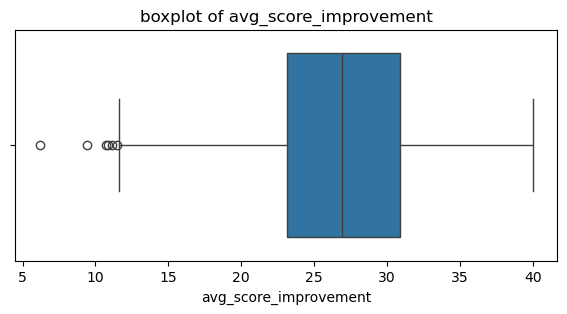

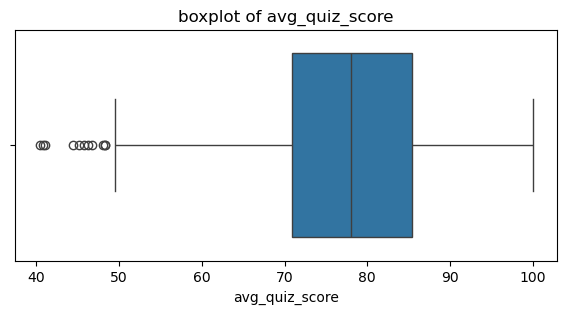

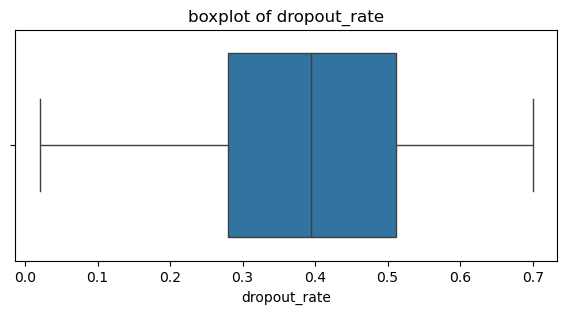

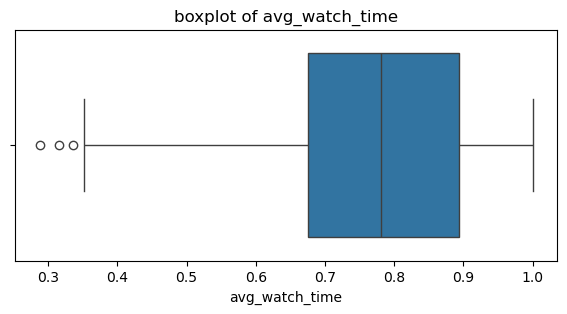

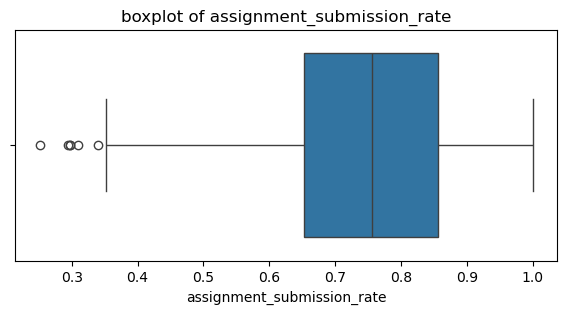

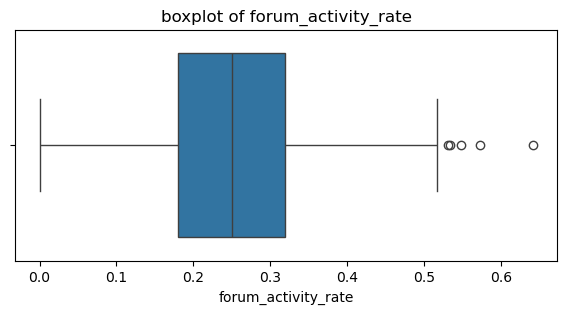

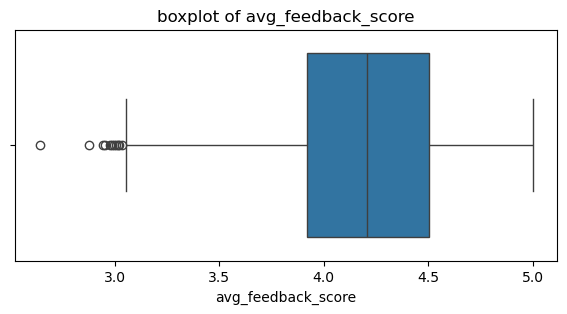

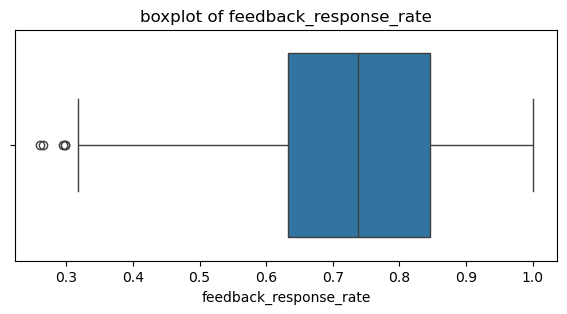

In [40]:
for col in numerical_cols:
    plt.figure(figsize=(7,3))
    sns.boxplot(x=df[col])
    plt.title(f'boxplot of {col}')
    plt.show()

In [41]:
instructor_courses=df.groupby('instructor_id')['course_id'].nunique()
print(instructor_courses)

instructor_id
I_001    16
I_002    10
I_003    14
I_004    10
I_005    13
         ..
I_116    13
I_117    11
I_118    14
I_119    12
I_120     9
Name: course_id, Length: 120, dtype: int64


In [42]:
instructor_courses = (
    df.groupby('instructor_id')
    .agg(total_courses=('course_id', 'nunique'))
    .reset_index()
)

instructor_courses.head(10)

,instructor_id,total_courses
0,I_001,16
1,I_002,10
2,I_003,14
3,I_004,10
4,I_005,13
5,I_006,13
6,I_007,9
7,I_008,14
8,I_009,12
9,I_010,10


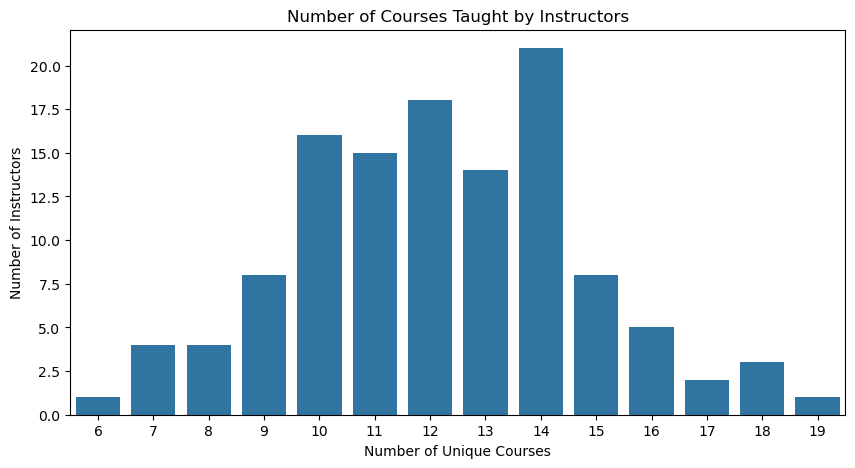

In [45]:
course_counts = instructor_courses['total_courses'].value_counts().sort_index()

plt.figure(figsize=(10, 5))

sns.barplot(
    x=course_counts.index,
    y=course_counts.values
)

plt.title('Number of Courses Taught by Instructors')
plt.xlabel('Number of Unique Courses')
plt.ylabel('Number of Instructors')

plt.show()

In [46]:
instructor_courses = (
    df.groupby('instructor_id')['course_id']
    .nunique()
    .reset_index(name='total_courses')
)

instructor_courses

,instructor_id,total_courses
0,I_001,16
1,I_002,10
2,I_003,14
3,I_004,10
4,I_005,13
...,...,...
115,I_116,13
116,I_117,11
117,I_118,14
118,I_119,12


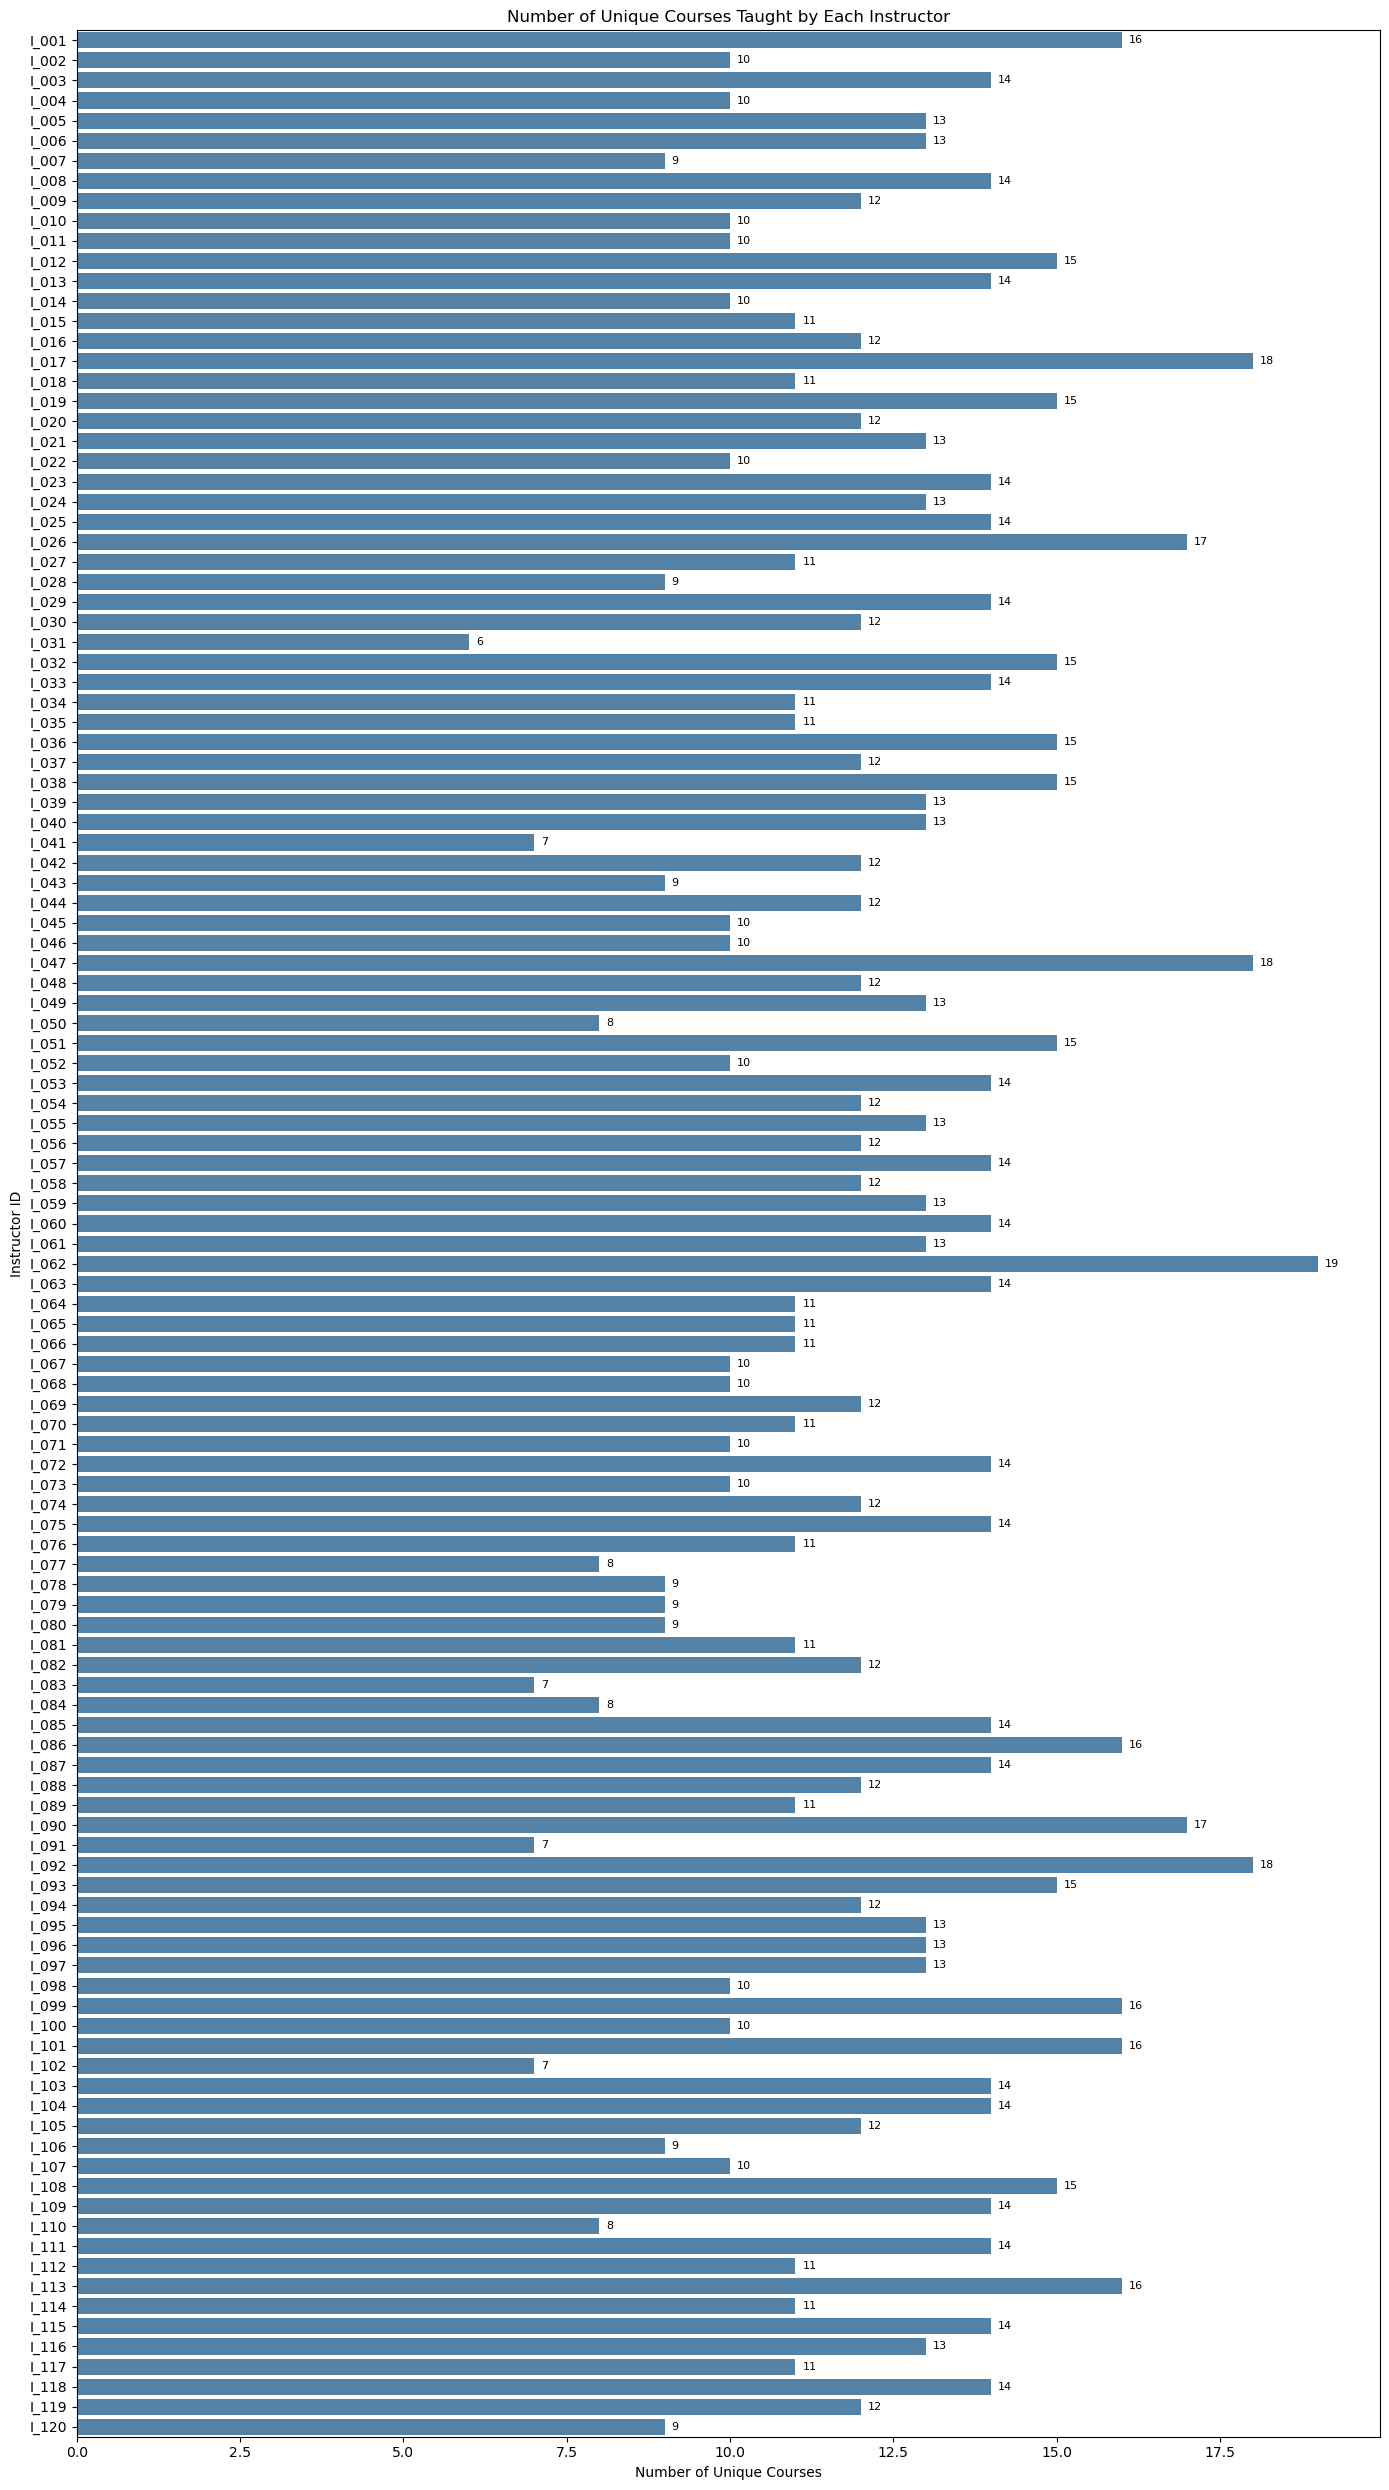

In [48]:
plt.figure(figsize=(14, 25))

ax = sns.barplot(
    data=instructor_courses,
    x='total_courses',
    y='instructor_id',
    color='steelblue'
)

# Add labels at the end of every bar
ax.bar_label(ax.containers[0], padding=5, fontsize=8)

plt.title('Number of Unique Courses Taught by Each Instructor')
plt.xlabel('Number of Unique Courses')
plt.ylabel('Instructor ID')

plt.tight_layout()
plt.show()

In [49]:
instructor_batches = (
    df.groupby('instructor_id')['batch_id']
    .nunique()
    .reset_index(name='total_batches')
)

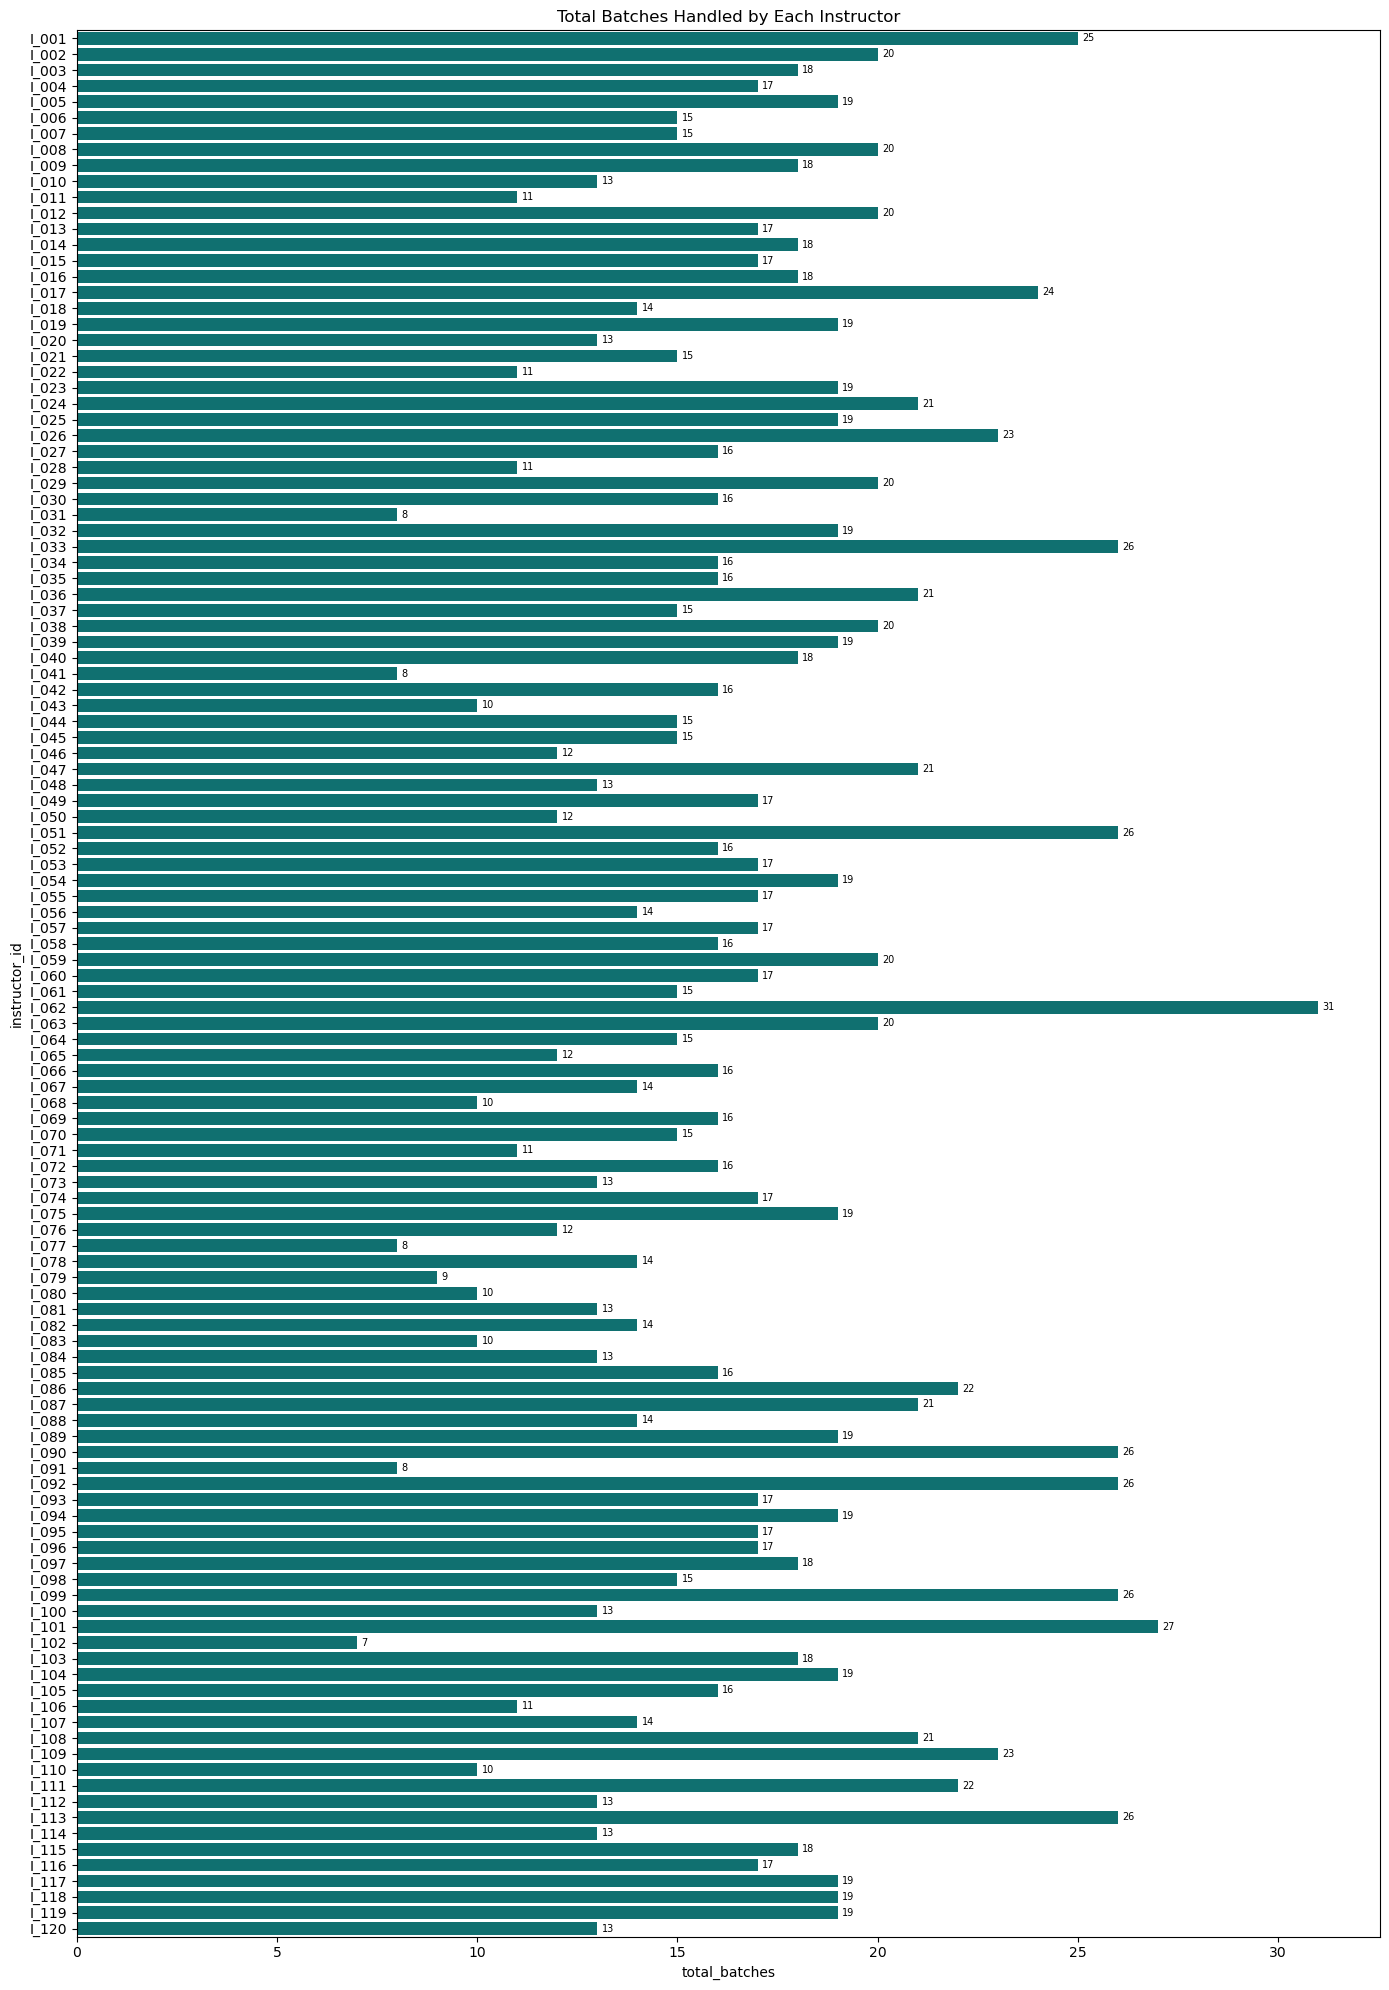

In [50]:
plt.figure(figsize=(14, 20))

ax = sns.barplot(
    data=instructor_batches,
    x='total_batches',
    y='instructor_id',
    color='teal'
)

ax.bar_label(ax.containers[0], padding=3, fontsize=7)

plt.title('Total Batches Handled by Each Instructor')
plt.tight_layout()
plt.show()

In [142]:
instructor_completion = (
    df.groupby('instructor_id')['completion_rate']
    .mean()
    .reset_index()
)

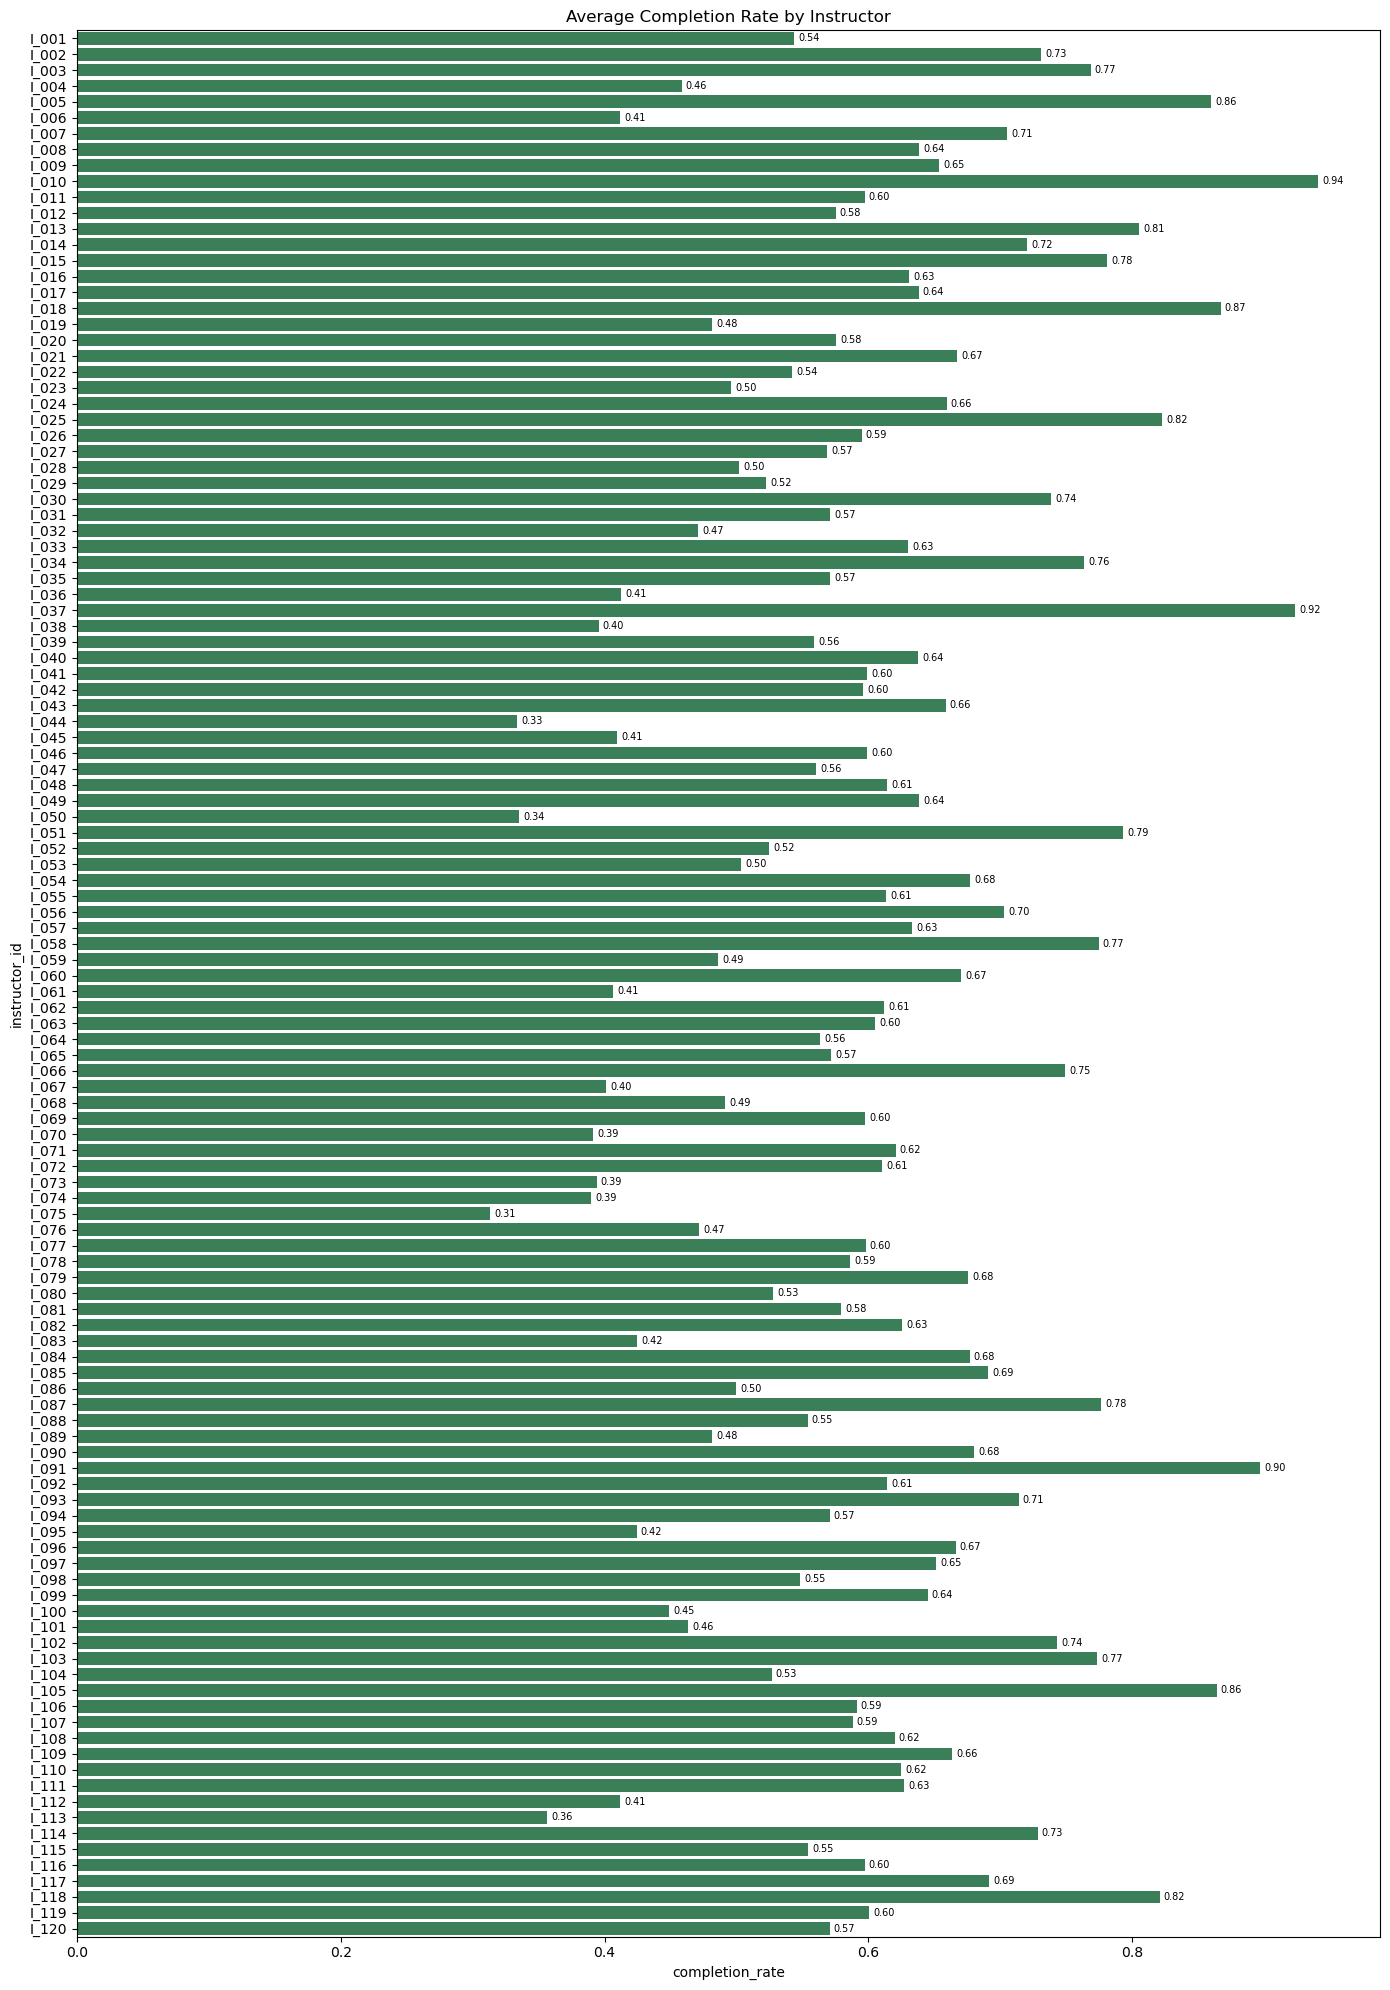

In [58]:
plt.figure(figsize=(14, 20))

ax = sns.barplot(
    data=instructor_completion,
    x='completion_rate',
    y='instructor_id',
    color='seagreen'
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=7)

plt.title('Average Completion Rate by Instructor')
plt.tight_layout()
plt.show()

In [143]:
instructor_dropout = (
    df.groupby('instructor_id')['dropout_rate']
    .mean()
    .reset_index()
    
)

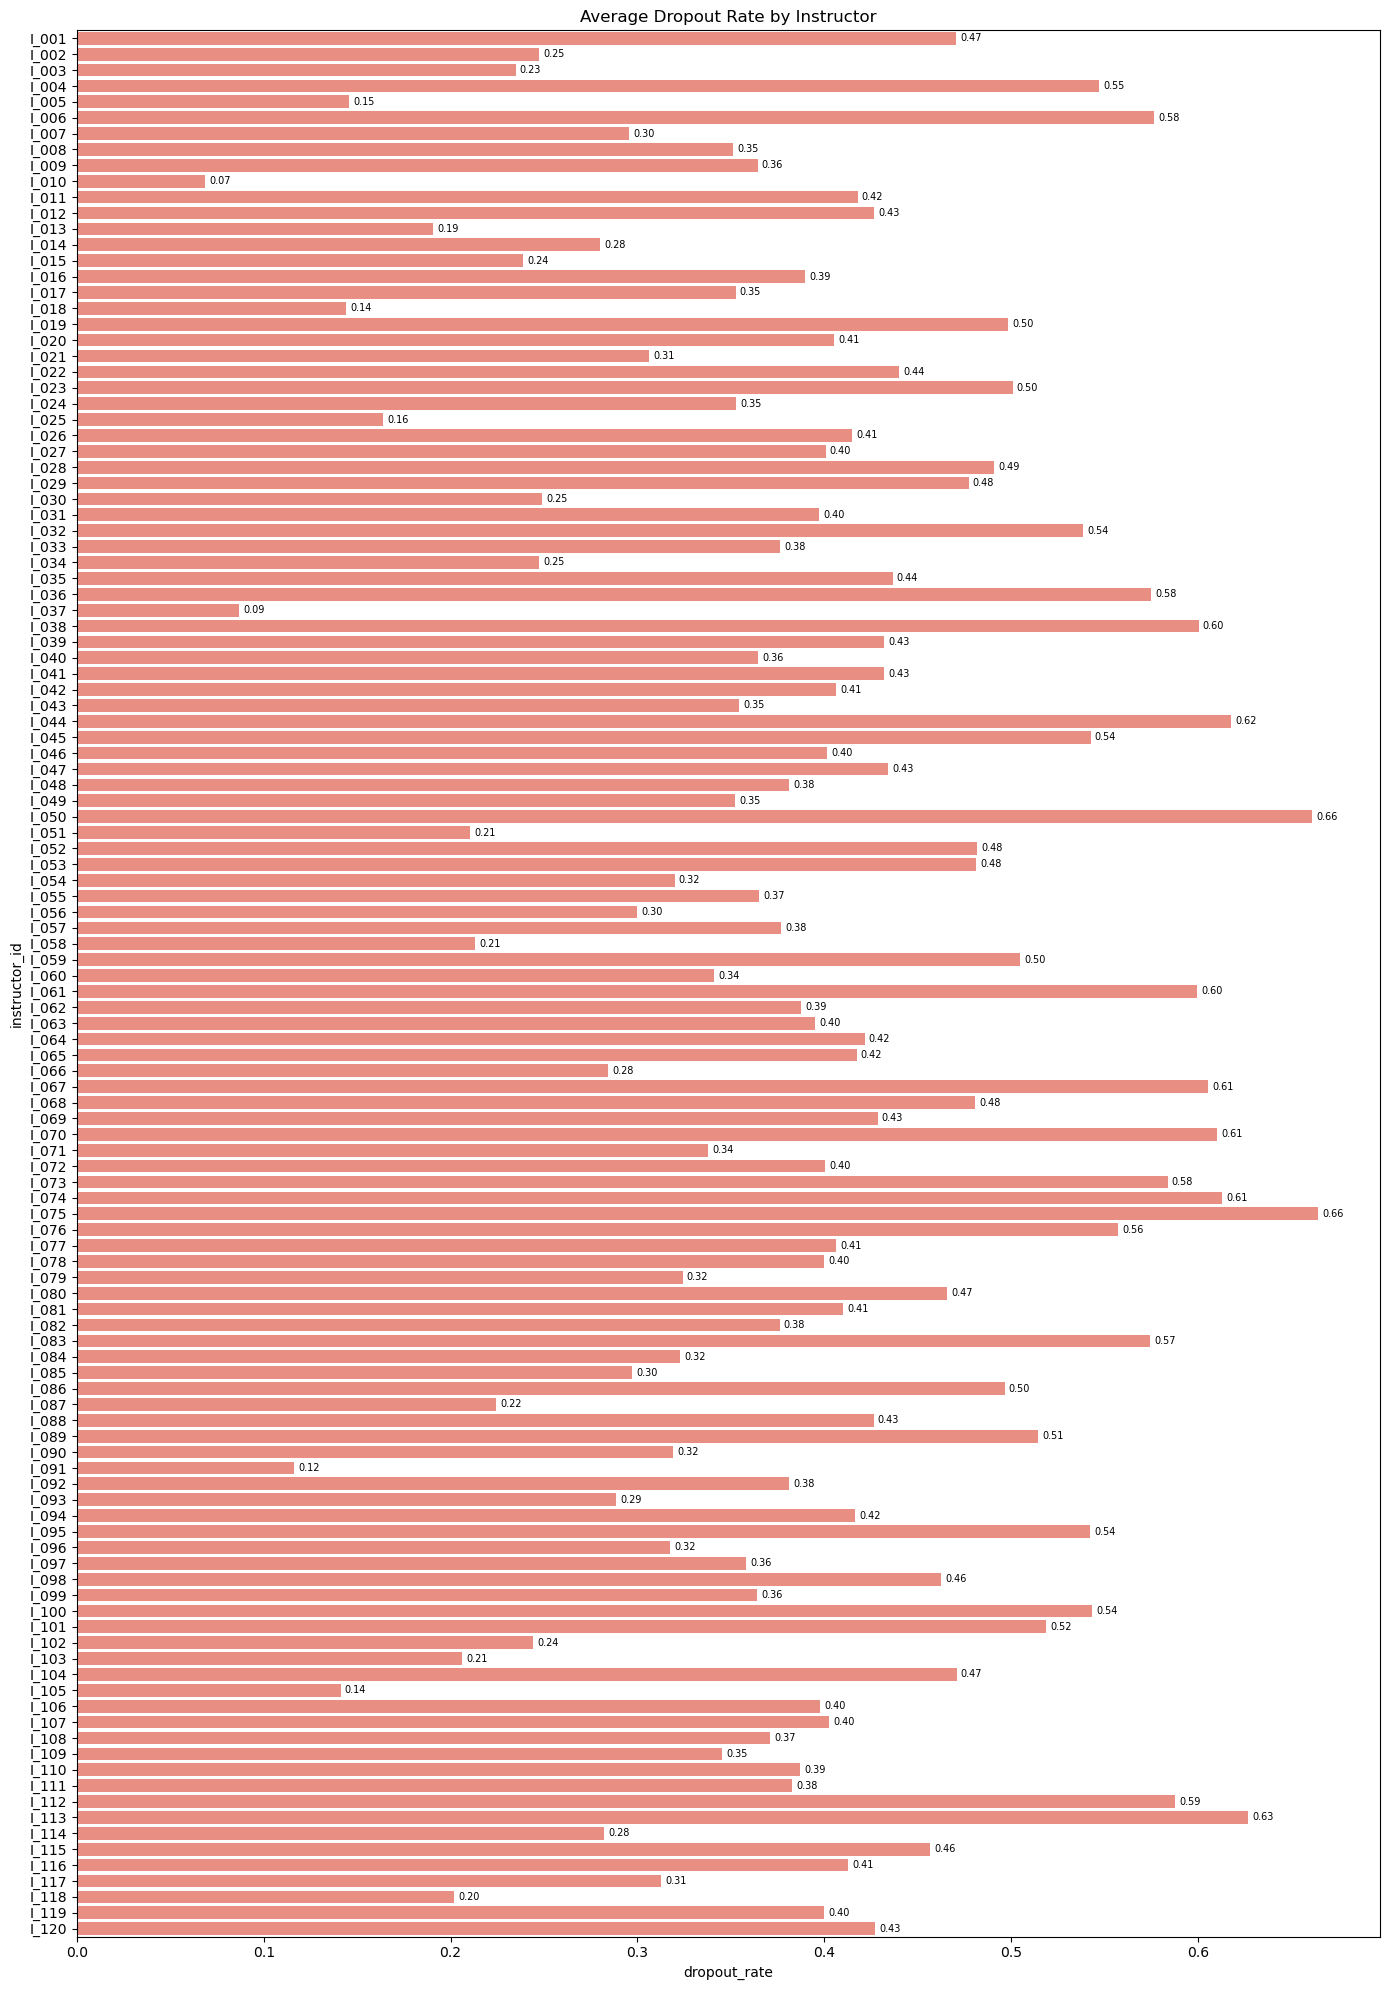

In [63]:
plt.figure(figsize=(14, 20))

ax = sns.barplot(
    data=instructor_dropout,
    x='dropout_rate',
    y='instructor_id',
    color='salmon'
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=7)

plt.title('Average Dropout Rate by Instructor')
plt.tight_layout()
plt.show()

In [64]:
instructor_quiz = (
    df.groupby('instructor_id')['avg_quiz_score']
    .mean()
    .reset_index()
    .sort_values('avg_quiz_score', ascending=False)
)

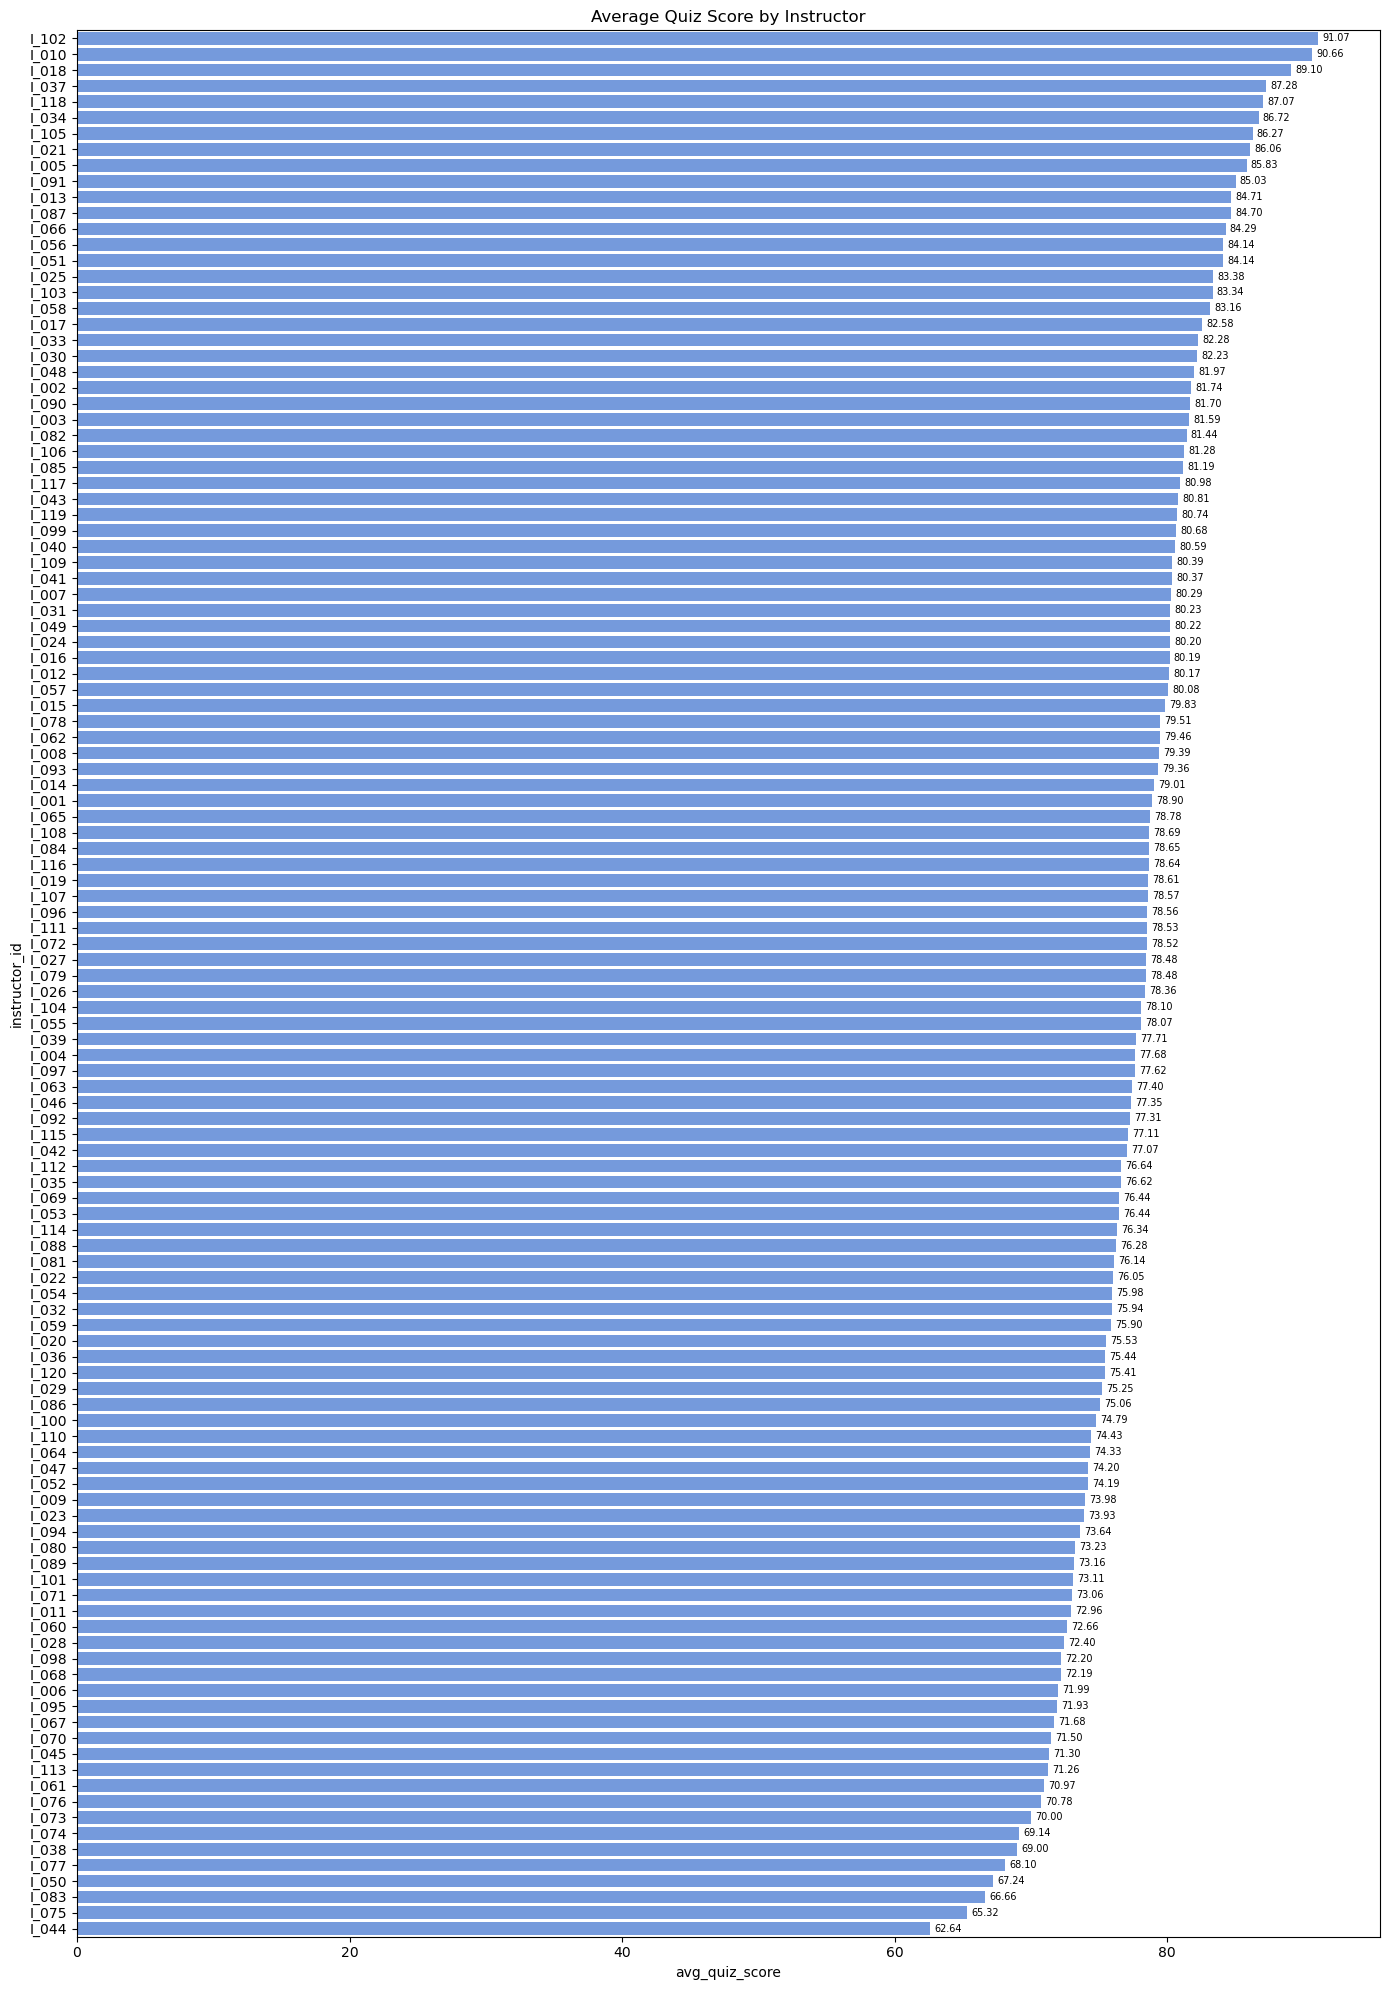

In [67]:
plt.figure(figsize=(14, 20))

ax=sns.barplot(
    data=instructor_quiz,
    x='avg_quiz_score',
    y='instructor_id',
    color='cornflowerblue'
)
ax.bar_label(ax.containers[0], fmt='%.2f', padding=3, fontsize=7)


plt.title('Average Quiz Score by Instructor')
plt.tight_layout()
plt.show()

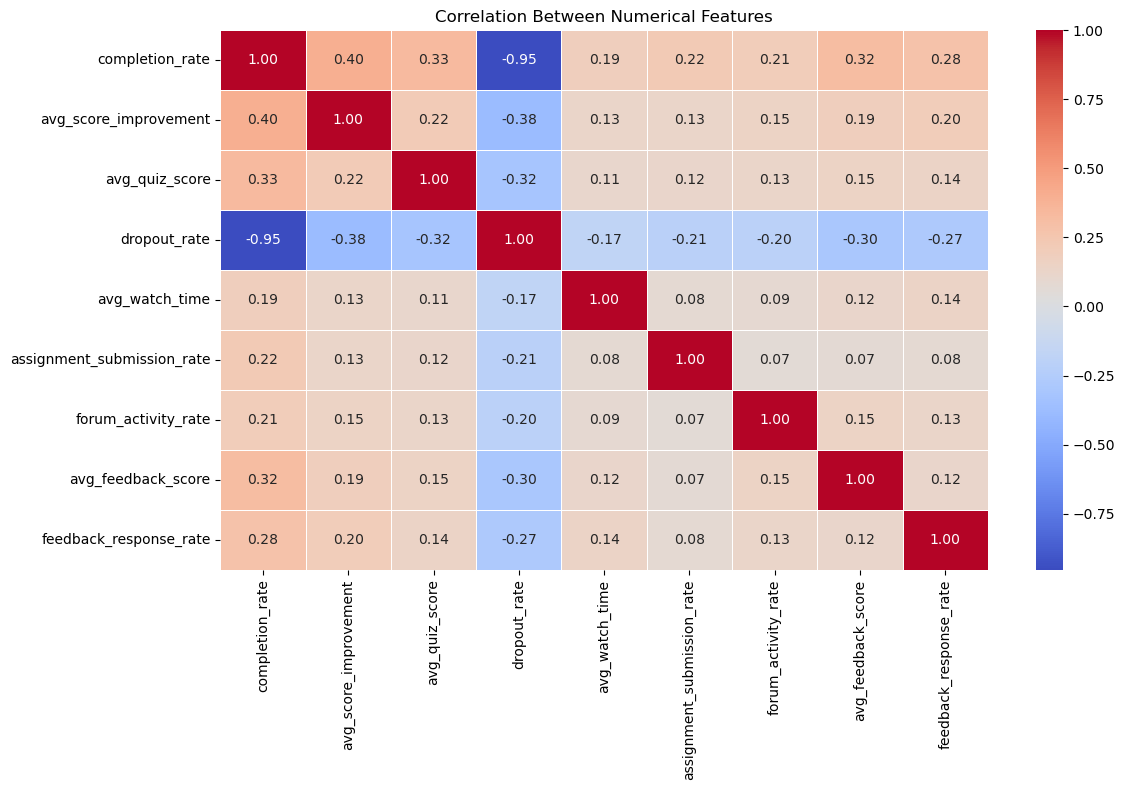

In [68]:
plt.figure(figsize=(12, 8))

corr = df.select_dtypes(include='number').corr()

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Between Numerical Features')
plt.tight_layout()
plt.show()

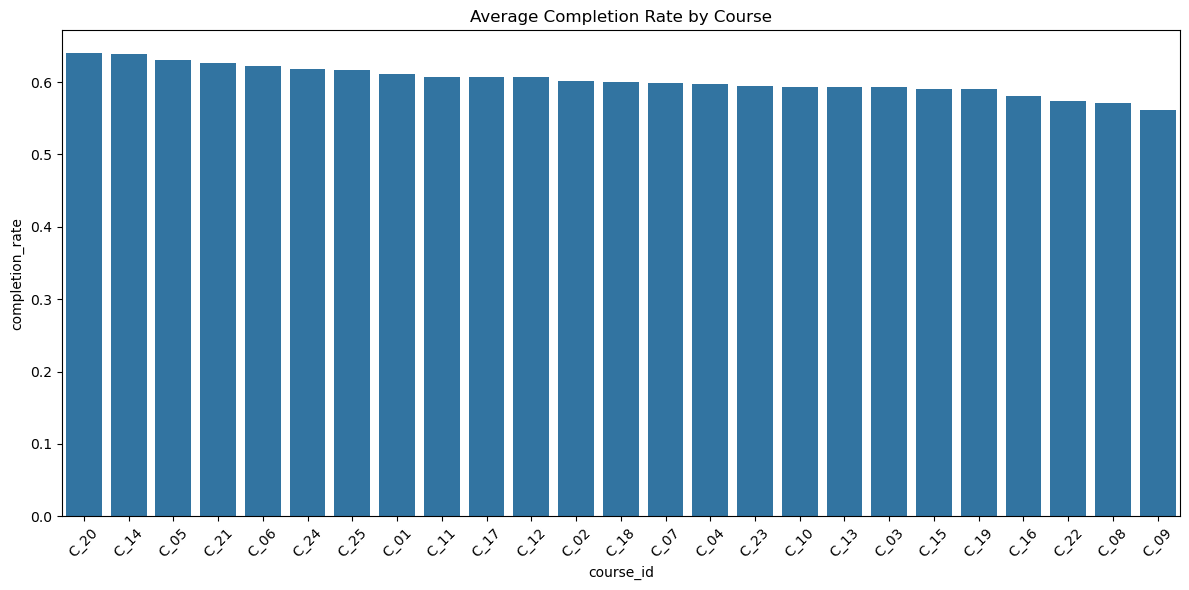

In [69]:
course_completion = (
    df.groupby('course_id')['completion_rate']
    .mean()
    .reset_index()
    .sort_values('completion_rate', ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=course_completion,
    x='course_id',
    y='completion_rate'
)

plt.xticks(rotation=45)
plt.title('Average Completion Rate by Course')
plt.tight_layout()
plt.show()

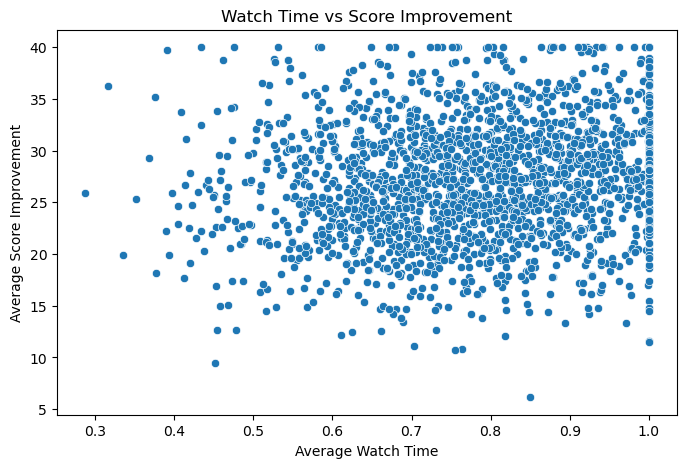

In [71]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='avg_watch_time',
    y='avg_score_improvement'
)

plt.title('Watch Time vs Score Improvement')
plt.xlabel('Average Watch Time')
plt.ylabel('Average Score Improvement')

plt.show()

In [72]:
    instructor_comparison = (
    df.groupby('instructor_id')
    .agg({
        'completion_rate': 'mean',
        'dropout_rate': 'mean',
        'avg_quiz_score': 'mean',
        'avg_feedback_score': 'mean',
        'avg_watch_time': 'mean'
    })
    .reset_index()
)

instructor_comparison.head()

,instructor_id,completion_rate,dropout_rate,avg_quiz_score,avg_feedback_score,avg_watch_time
0,I_001,0.543884,0.470596,78.900200,4.217736,0.766508
1,I_002,0.730875,0.247195,81.737200,4.342990,0.837395
2,I_003,0.768450,0.234833,81.590933,4.450039,0.818444
3,I_004,0.458329,0.547265,77.680312,4.076394,0.793135
4,I_005,0.859753,0.145726,85.828153,4.202521,0.847021


In [73]:
instructor_analysis = (
    df.groupby('instructor_id')
    .agg(
        total_courses=('course_id', 'nunique'),
        total_batches=('batch_id', 'nunique'),
        avg_completion=('completion_rate', 'mean'),
        avg_dropout=('dropout_rate', 'mean'),
        avg_quiz_score=('avg_quiz_score', 'mean'),
        avg_score_improvement=('avg_score_improvement', 'mean'),
        avg_watch_time=('avg_watch_time', 'mean'),
        avg_feedback=('avg_feedback_score', 'mean')
    )
    .reset_index()
)

instructor_analysis.head()

,instructor_id,total_courses,total_batches,avg_completion,avg_dropout,avg_quiz_score,avg_score_improvement,avg_watch_time,avg_feedback
0,I_001,16,25,0.543884,0.470596,78.900200,26.641460,0.766508,4.217736
1,I_002,10,20,0.730875,0.247195,81.737200,30.166250,0.837395,4.342990
2,I_003,14,18,0.768450,0.234833,81.590933,29.977811,0.818444,4.450039
3,I_004,10,17,0.458329,0.547265,77.680312,22.912024,0.793135,4.076394
4,I_005,13,19,0.859753,0.145726,85.828153,32.588663,0.847021,4.202521


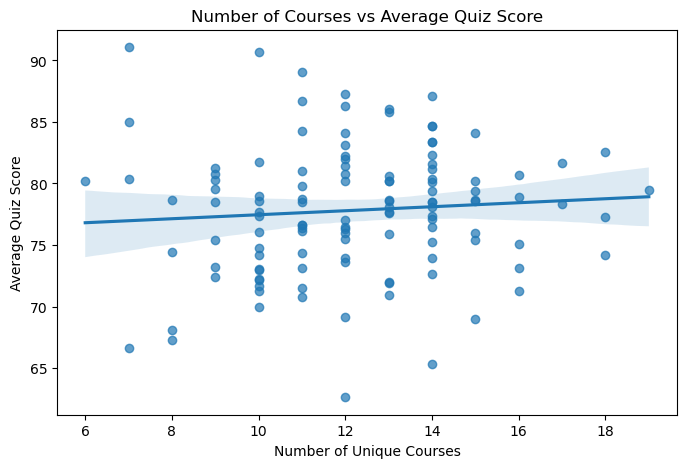

In [75]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=instructor_analysis,
    x='total_courses',
    y='avg_quiz_score',
    scatter_kws={'alpha': 0.7}
)

plt.title('Number of Courses vs Average Quiz Score')
plt.xlabel('Number of Unique Courses')
plt.ylabel('Average Quiz Score')

plt.show()

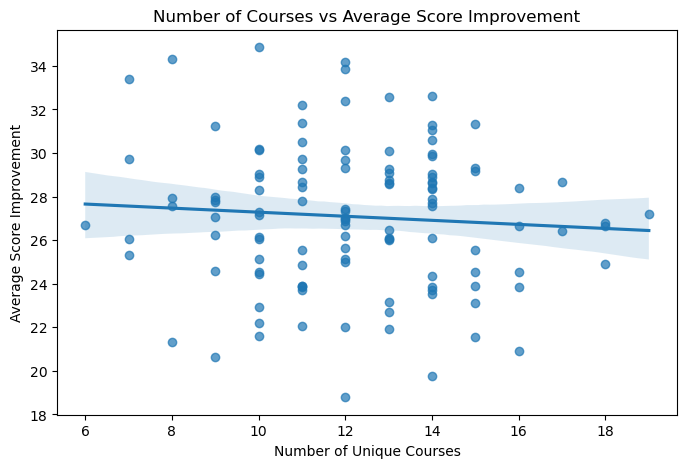

In [76]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=instructor_analysis,
    x='total_courses',
    y='avg_score_improvement',
    scatter_kws={'alpha': 0.7}
)

plt.title('Number of Courses vs Average Score Improvement')
plt.xlabel('Number of Unique Courses')
plt.ylabel('Average Score Improvement')

plt.show()

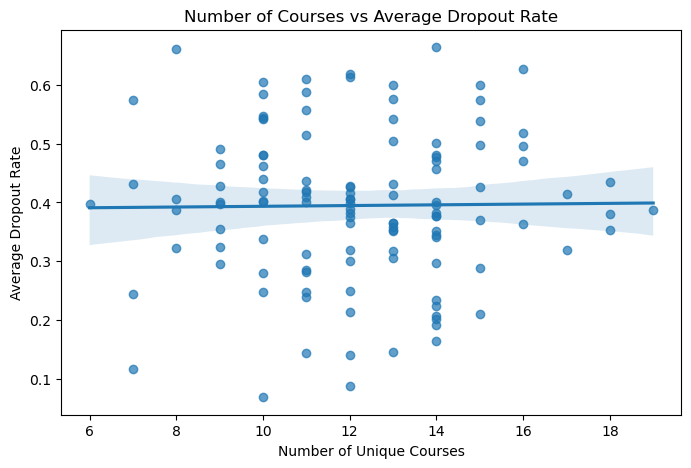

In [77]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=instructor_analysis,
    x='total_courses',
    y='avg_dropout',
    scatter_kws={'alpha': 0.7}
)

plt.title('Number of Courses vs Average Dropout Rate')
plt.xlabel('Number of Unique Courses')
plt.ylabel('Average Dropout Rate')

plt.show()

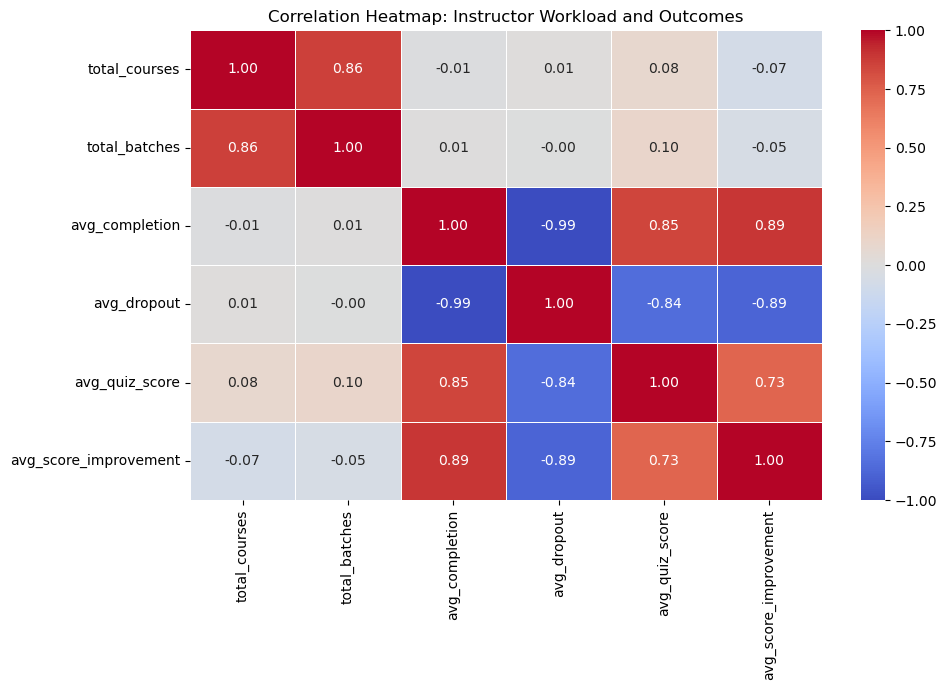

In [79]:
# Calculate correlation matrix
correlation_matrix = instructor_analysis[
    [
        'total_courses',
        'total_batches',
        'avg_completion',
        'avg_dropout',
        'avg_quiz_score',
        'avg_score_improvement'
    ]
].corr(method='pearson')

# Plot correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap: Instructor Workload and Outcomes')
plt.tight_layout()
plt.show()

In [80]:
# Select numerical columns
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Calculate outlier limits
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    print(f"{col}: {len(outliers)} potential outliers")

completion_rate: 0 potential outliers
avg_score_improvement: 6 potential outliers
avg_quiz_score: 11 potential outliers
dropout_rate: 0 potential outliers
avg_watch_time: 3 potential outliers
assignment_submission_rate: 6 potential outliers
forum_activity_rate: 5 potential outliers
avg_feedback_score: 11 potential outliers
feedback_response_rate: 5 potential outliers


In [81]:
# Columns to inspect
numerical_cols = df.select_dtypes(include=['float64', 'int64']).columns

# Identify and display potential outliers
for col in numerical_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) | (df[col] > upper)
    ]

    if len(outliers) > 0:
        print(f"\nFeature: {col}")
        print(f"Lower limit: {lower:.4f}")
        print(f"Upper limit: {upper:.4f}")
        print(f"Number of outliers: {len(outliers)}")

        display(
            outliers[
                ['instructor_id', 'course_id', 'batch_id', col]
            ]
        )


Feature: avg_score_improvement
Lower limit: 11.4833
Upper limit: 42.5269
Number of outliers: 6


,instructor_id,course_id,batch_id,avg_score_improvement
598,I_035,C_06,B_1343,10.8366
736,I_044,C_05,B_0076,10.6946
1230,I_074,C_08,B_1866,6.1592
1243,I_075,C_07,B_1037,9.4471
1443,I_089,C_20,B_0964,11.1274
1870,I_113,C_12,B_1869,11.4750



Feature: avg_quiz_score
Lower limit: 49.0776
Upper limit: 107.2643
Number of outliers: 11


,instructor_id,course_id,batch_id,avg_quiz_score
165,I_009,C_23,B_0488,45.7215
694,I_040,C_18,B_0559,44.3755
746,I_044,C_22,B_1309,40.8421
787,I_047,C_17,B_1131,46.2420
1017,I_060,C_24,B_1332,48.1187
1227,I_074,C_05,B_1429,48.2430
1270,I_077,C_03,B_0969,41.0982
1343,I_083,C_12,B_1631,48.3473
1532,I_094,C_05,B_1996,45.1507
1656,I_101,C_02,B_1181,46.7699



Feature: avg_watch_time
Lower limit: 0.3464
Upper limit: 1.2229
Number of outliers: 3


,instructor_id,course_id,batch_id,avg_watch_time
883,I_053,C_07,B_1528,0.3358
953,I_057,C_10,B_0882,0.2874
1342,I_083,C_12,B_1594,0.3161


... (4 outputs left out)


Feature: avg_feedback_score
Lower limit: 3.0422
Upper limit: 5.3802
Number of outliers: 11


,instructor_id,course_id,batch_id,avg_feedback_score
620,I_036,C_13,B_1142,3.0074
662,I_038,C_24,B_1324,2.9529
738,I_044,C_09,B_0160,3.0324
743,I_044,C_16,B_0679,2.8784
829,I_050,C_06,B_1104,2.9986
1176,I_070,C_15,B_1279,2.6399
1242,I_075,C_05,B_0876,3.0140
1351,I_084,C_10,B_1071,2.9453
1591,I_097,C_11,B_1480,3.0221
1919,I_116,C_11,B_0622,2.9765



Feature: feedback_response_rate
Lower limit: 0.3145
Upper limit: 1.1648
Number of outliers: 5


,instructor_id,course_id,batch_id,feedback_response_rate
1130,I_067,C_08,B_0840,0.2644
1138,I_067,C_19,B_1654,0.2979
1342,I_083,C_12,B_1594,0.2953
1858,I_113,C_04,B_0451,0.2599
1912,I_115,C_24,B_1454,0.2977


In [82]:
# Features used for Instructor Effectiveness Score

features = [
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate',
    'completion_rate',
    'dropout_rate'
]

# Aggregate batch-level data into instructor-level data

instructor_df = (
    df.groupby('instructor_id')
    .agg(
        avg_score_improvement=('avg_score_improvement', 'mean'),
        avg_quiz_score=('avg_quiz_score', 'mean'),
        avg_watch_time=('avg_watch_time', 'mean'),
        assignment_submission_rate=('assignment_submission_rate', 'mean'),
        forum_activity_rate=('forum_activity_rate', 'mean'),
        avg_feedback_score=('avg_feedback_score', 'mean'),
        feedback_response_rate=('feedback_response_rate', 'mean'),
        completion_rate=('completion_rate', 'mean'),
        dropout_rate=('dropout_rate', 'mean'),

        total_batches=('batch_id', 'nunique'),
        total_courses=('course_id', 'nunique')
    )
    .reset_index()
)

print("Instructor-level dataset shape:", instructor_df.shape)

instructor_df.head()

Instructor-level dataset shape: (120, 12)


,instructor_id,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,completion_rate,dropout_rate,total_batches,total_courses
0,I_001,26.641460,78.900200,0.766508,0.726892,0.240540,4.217736,0.694860,0.543884,0.470596,25,16
1,I_002,30.166250,81.737200,0.837395,0.774395,0.289615,4.342990,0.784335,0.730875,0.247195,20,10
2,I_003,29.977811,81.590933,0.818444,0.779606,0.296217,4.450039,0.812122,0.768450,0.234833,18,14
3,I_004,22.912024,77.680312,0.793135,0.758318,0.226235,4.076394,0.721465,0.458329,0.547265,17,10
4,I_005,32.588663,85.828153,0.847021,0.876932,0.333526,4.202521,0.784195,0.859753,0.145726,19,13


In [84]:
print("Dataset Shape:", instructor_df.shape)

print("\nMissing Values:")
print(instructor_df.isnull().sum())

print("\nDescriptive Statistics:")
display(instructor_df[features].describe())

Dataset Shape: (120, 12)

Missing Values:
instructor_id                 0
avg_score_improvement         0
avg_quiz_score                0
avg_watch_time                0
assignment_submission_rate    0
forum_activity_rate           0
avg_feedback_score            0
feedback_response_rate        0
completion_rate               0
dropout_rate                  0
total_batches                 0
total_courses                 0
dtype: int64

Descriptive Statistics:


,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,completion_rate,dropout_rate
count,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000,120.000000
mean,27.081174,77.816950,0.775986,0.751370,0.250758,4.204834,0.734985,0.602577,0.394890
std,3.262538,5.203222,0.048667,0.059036,0.038249,0.184735,0.061947,0.132049,0.127827
min,18.792540,62.635553,0.655374,0.559460,0.126937,3.733393,0.589533,0.313395,0.068515
25%,24.794555,74.299335,0.745443,0.714695,0.228256,4.091257,0.688958,0.524229,0.319619
50%,27.186674,78.420375,0.779380,0.753622,0.249718,4.203793,0.742045,0.599069,0.399885
75%,29.094981,80.754370,0.804022,0.788981,0.273538,4.329879,0.784230,0.676018,0.478087
max,34.856738,91.071743,0.903747,0.924763,0.343262,4.641984,0.891862,0.940785,0.664305


In [85]:
# Check minimum and maximum values of all nine features

range_check = pd.DataFrame({
    'Minimum': instructor_df[features].min(),
    'Maximum': instructor_df[features].max(),
    'Mean': instructor_df[features].mean(),
    'Standard Deviation': instructor_df[features].std()
})

display(range_check.round(4))

,Minimum,Maximum,Mean,Standard Deviation
avg_score_improvement,18.7925,34.8567,27.0812,3.2625
avg_quiz_score,62.6356,91.0717,77.8169,5.2032
avg_watch_time,0.6554,0.9037,0.7760,0.0487
assignment_submission_rate,0.5595,0.9248,0.7514,0.0590
forum_activity_rate,0.1269,0.3433,0.2508,0.0382
avg_feedback_score,3.7334,4.6420,4.2048,0.1847
feedback_response_rate,0.5895,0.8919,0.7350,0.0619
completion_rate,0.3134,0.9408,0.6026,0.1320
dropout_rate,0.0685,0.6643,0.3949,0.1278


In [88]:
from sklearn.preprocessing import MinMaxScaler

# Create a separate normalized dataset
normalized_df = instructor_df[['instructor_id']].copy()

# Positive indicators
positive_features = [
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate',
    'completion_rate'
]

scaler = MinMaxScaler()

normalized_df[positive_features] = scaler.fit_transform(
    instructor_df[positive_features]
)

# Negative indicator: reverse dropout rate
dropout_min = instructor_df['dropout_rate'].min()
dropout_max = instructor_df['dropout_rate'].max()

normalized_df['dropout_rate'] = (
    (dropout_max - instructor_df['dropout_rate']) /
    (dropout_max - dropout_min)
)

display("normalized table",normalized_df.head())

'normalized table'

,instructor_id,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,completion_rate,dropout_rate
0,I_001,0.488597,0.571970,0.447449,0.458338,0.525151,0.533070,0.348385,0.367378,0.325130
1,I_002,0.708016,0.671737,0.732855,0.588375,0.752009,0.670925,0.644338,0.665424,0.700096
2,I_003,0.696286,0.666594,0.656556,0.602639,0.782527,0.788744,0.736249,0.725315,0.720845
3,I_004,0.256439,0.529071,0.554656,0.544364,0.459025,0.377509,0.436385,0.231012,0.196446
4,I_005,0.858812,0.815602,0.771611,0.869065,0.954997,0.516324,0.643874,0.870843,0.870406


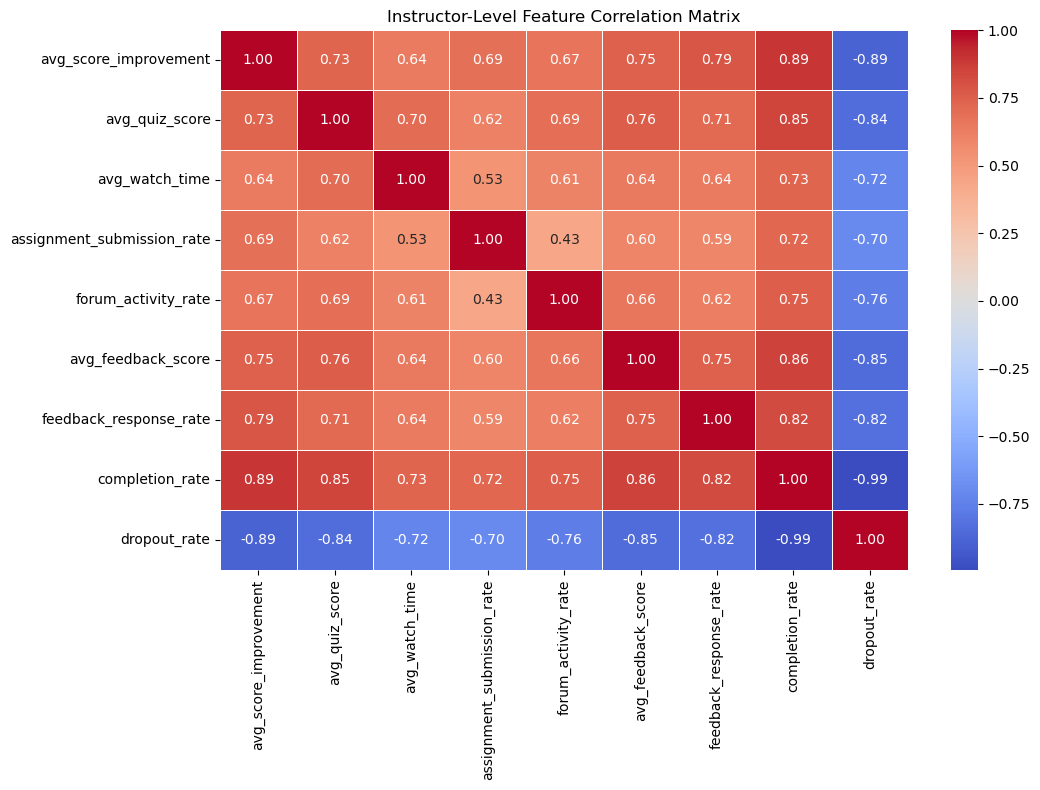

In [89]:
import matplotlib.pyplot as plt
import seaborn as sns

correlation_matrix = instructor_df[features].corr()

plt.figure(figsize=(11, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    center=0,
    linewidths=0.5
)

plt.title('Instructor-Level Feature Correlation Matrix')
plt.tight_layout()
plt.show()

In [90]:
correlation_pairs = (
    correlation_matrix
    .where(
        ~np.eye(correlation_matrix.shape[0], dtype=bool)
    )
    .stack()
    .reset_index()
)

correlation_pairs.columns = [
    'Feature 1', 'Feature 2', 'Correlation'
]

correlation_pairs['Absolute Correlation'] = (
    correlation_pairs['Correlation'].abs()
)

correlation_pairs = (
    correlation_pairs
    .sort_values('Absolute Correlation', ascending=False)
)

display(correlation_pairs.head(15).round(4))

,Feature 1,Feature 2,Correlation,Absolute Correlation
71,dropout_rate,completion_rate,-0.9939,0.9939
63,completion_rate,dropout_rate,-0.9939,0.9939
6,avg_score_improvement,completion_rate,0.8936,0.8936
56,completion_rate,avg_score_improvement,0.8936,0.8936
64,dropout_rate,avg_score_improvement,-0.8872,0.8872
7,avg_score_improvement,dropout_rate,-0.8872,0.8872
46,avg_feedback_score,completion_rate,0.8554,0.8554
61,completion_rate,avg_feedback_score,0.8554,0.8554
47,avg_feedback_score,dropout_rate,-0.8513,0.8513
69,dropout_rate,avg_feedback_score,-0.8513,0.8513


In [91]:
# Combine completion and dropout into one retention indicator

normalized_df['retention_score'] = normalized_df[
    ['completion_rate', 'dropout_rate']
].mean(axis=1)

# Remove the original two columns
normalized_df = normalized_df.drop(
    columns=['completion_rate', 'dropout_rate']
)

# Define the final 8 indicators
final_features = [
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_watch_time',
    'assignment_submission_rate',
    'forum_activity_rate',
    'avg_feedback_score',
    'feedback_response_rate',
    'retention_score'
]

print("Final number of indicators:", len(final_features))
print("\nFinal feature dataset:")
display(normalized_df[['instructor_id'] + final_features].head())

print("\nDescriptive statistics:")
display(normalized_df[final_features].describe().T.round(4))

Final number of indicators: 8

Final feature dataset:


,instructor_id,avg_score_improvement,avg_quiz_score,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate,retention_score
0,I_001,0.488597,0.571970,0.447449,0.458338,0.525151,0.533070,0.348385,0.346254
1,I_002,0.708016,0.671737,0.732855,0.588375,0.752009,0.670925,0.644338,0.682760
2,I_003,0.696286,0.666594,0.656556,0.602639,0.782527,0.788744,0.736249,0.723080
3,I_004,0.256439,0.529071,0.554656,0.544364,0.459025,0.377509,0.436385,0.213729
4,I_005,0.858812,0.815602,0.771611,0.869065,0.954997,0.516324,0.643874,0.870624



Descriptive statistics:


,count,mean,std,min,25%,50%,75%,max
avg_score_improvement,120.0,0.5160,0.2031,0.0,0.3736,0.5225,0.6413,1.0
avg_quiz_score,120.0,0.5339,0.1830,0.0,0.4102,0.5551,0.6372,1.0
avg_watch_time,120.0,0.4856,0.1959,0.0,0.3626,0.4993,0.5985,1.0
assignment_submission_rate,120.0,0.5253,0.1616,0.0,0.4249,0.5315,0.6283,1.0
forum_activity_rate,120.0,0.5724,0.1768,0.0,0.4684,0.5676,0.6777,1.0
avg_feedback_score,120.0,0.5189,0.2033,0.0,0.3939,0.5177,0.6565,1.0
feedback_response_rate,120.0,0.4811,0.2049,0.0,0.3289,0.5045,0.6440,1.0
retention_score,120.0,0.4566,0.2122,0.0,0.3232,0.4466,0.5767,1.0


In [93]:
equal_weights = pd.Series(
    1 / len(final_features),
    index=final_features,
    name='Equal Weight'
)

print("Equal Weights:")
display(equal_weights.to_frame().round(4))

Equal Weights:


,Equal Weight
avg_score_improvement,0.125
avg_quiz_score,0.125
avg_watch_time,0.125
assignment_submission_rate,0.125
forum_activity_rate,0.125
avg_feedback_score,0.125
feedback_response_rate,0.125
retention_score,0.125


In [94]:
# Prepare normalized data
X = normalized_df[final_features].copy()

# Calculate entropy weights
entropy_weights = {}

for col in final_features:

    values = X[col].values
    total = values.sum()

    # Handle a feature with no variation
    if total == 0 or values.max() == values.min():
        entropy_weights[col] = 0
        continue

    probabilities = values / total

    # Avoid log(0)
    probabilities = probabilities[probabilities > 0]

    n = len(values)
    entropy = -(1 / np.log(n)) * np.sum(
        probabilities * np.log(probabilities)
    )

    entropy_weights[col] = 1 - entropy

# Convert to Series
entropy_weights = pd.Series(entropy_weights)

# Normalize weights so that their sum is 1
if entropy_weights.sum() > 0:
    entropy_weights = entropy_weights / entropy_weights.sum()
else:
    entropy_weights[:] = 1 / len(final_features)

entropy_weights.name = 'Entropy Weight'

print("Entropy Weights:")
display(entropy_weights.to_frame().round(4))

Entropy Weights:


,Entropy Weight
avg_score_improvement,0.1300
avg_quiz_score,0.0988
avg_watch_time,0.1399
assignment_submission_rate,0.0813
forum_activity_rate,0.0809
avg_feedback_score,0.1319
feedback_response_rate,0.1561
retention_score,0.1811


In [95]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Standardize the indicators
scaler_pca = StandardScaler()
X_scaled = scaler_pca.fit_transform(X)

# Apply PCA
pca = PCA()
pca.fit(X_scaled)

# First principal component loadings
pc1_loadings = pd.Series(
    pca.components_[0],
    index=final_features
)

# Convert absolute loadings into weights
pca_weights = pc1_loadings.abs()

pca_weights = pca_weights / pca_weights.sum()
pca_weights.name = 'PCA Weight'

print("Variance explained by first principal component:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("\nPCA Weights:")
display(pca_weights.to_frame().round(4))

Variance explained by first principal component: 73.69 %

PCA Weights:


,PCA Weight
avg_score_improvement,0.1317
avg_quiz_score,0.1296
avg_watch_time,0.1166
assignment_submission_rate,0.1092
forum_activity_rate,0.1159
avg_feedback_score,0.1288
feedback_response_rate,0.1267
retention_score,0.1415


In [96]:
weight_comparison = pd.concat(
    [
        equal_weights,
        entropy_weights,
        pca_weights
    ],
    axis=1
)

print("Comparison of Weighting Methods:")
display(weight_comparison.round(4))

Comparison of Weighting Methods:


,Equal Weight,Entropy Weight,PCA Weight
avg_score_improvement,0.125,0.1300,0.1317
avg_quiz_score,0.125,0.0988,0.1296
avg_watch_time,0.125,0.1399,0.1166
assignment_submission_rate,0.125,0.0813,0.1092
forum_activity_rate,0.125,0.0809,0.1159
avg_feedback_score,0.125,0.1319,0.1288
feedback_response_rate,0.125,0.1561,0.1267
retention_score,0.125,0.1811,0.1415


In [97]:
# Compare the ranking of indicators under each method

weight_ranks = weight_comparison.rank(
    ascending=False,
    method='average'
)

print("Indicator Ranking Under Each Method:")
display(weight_ranks.astype(int))

# Spearman rank correlation between weighting methods

method_rank_correlation = weight_ranks.corr(
    method='spearman'
)

print("\nAgreement Between Weighting Methods:")
display(method_rank_correlation.round(4))

Indicator Ranking Under Each Method:


,Equal Weight,Entropy Weight,PCA Weight
avg_score_improvement,4,5,2
avg_quiz_score,4,6,3
avg_watch_time,4,3,6
assignment_submission_rate,4,7,8
forum_activity_rate,4,8,7
avg_feedback_score,4,4,4
feedback_response_rate,4,2,5
retention_score,4,1,1



Agreement Between Weighting Methods:


,Equal Weight,Entropy Weight,PCA Weight
Equal Weight,NaN,NaN,NaN
Entropy Weight,NaN,1.0000,0.5476
PCA Weight,NaN,0.5476,1.0000


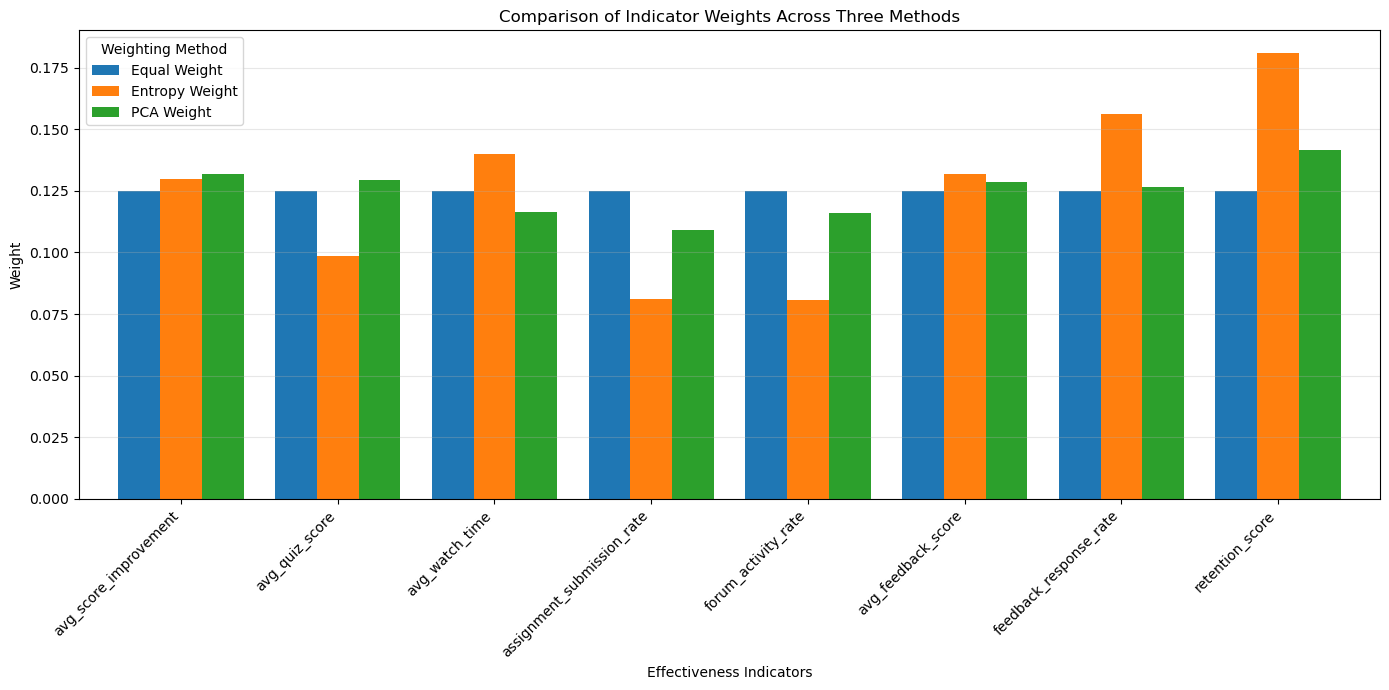

In [98]:
import matplotlib.pyplot as plt
import seaborn as sns

weight_comparison.plot(
    kind='bar',
    figsize=(14, 7),
    width=0.8
)

plt.title('Comparison of Indicator Weights Across Three Methods')
plt.xlabel('Effectiveness Indicators')
plt.ylabel('Weight')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Weighting Method')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
# Calculate weighted scores and convert them to a 0-100 scale

normalized_df['IES_Equal'] = (
    normalized_df[final_features] @ equal_weights
) * 100

normalized_df['IES_Entropy'] = (
    normalized_df[final_features] @ entropy_weights
) * 100

normalized_df['IES_PCA'] = (
    normalized_df[final_features] @ pca_weights
) * 100


# Create instructor-level IES comparison
ies_comparison = normalized_df[
    ['instructor_id', 'IES_Equal', 'IES_Entropy', 'IES_PCA']
].copy()

# Rank instructors (1 = highest effectiveness)
ies_comparison['Rank_Equal'] = (
    ies_comparison['IES_Equal'].rank(ascending=False, method='average')
)

ies_comparison['Rank_Entropy'] = (
    ies_comparison['IES_Entropy'].rank(ascending=False, method='average')
)

ies_comparison['Rank_PCA'] = (
    ies_comparison['IES_PCA'].rank(ascending=False, method='average')
)

print("IES Comparison for All Instructors:")
display(ies_comparison.head(10).round(3))

IES Comparison for All Instructors:


,instructor_id,IES_Equal,IES_Entropy,IES_PCA,Rank_Equal,Rank_Entropy,Rank_PCA
0,I_001,46.490,44.977,46.335,72.0,75.0,71.0
1,I_002,68.138,68.233,68.182,19.0,19.0,19.0
2,I_003,70.658,71.044,70.833,15.0,15.0,15.0
3,I_004,42.140,40.122,41.382,86.0,90.0,90.0
4,I_005,78.761,77.436,78.566,5.0,6.0,6.0
5,I_006,26.666,24.826,26.325,111.0,113.0,111.0
6,I_007,64.634,63.842,64.599,26.0,26.0,25.0
7,I_008,59.689,59.667,59.665,34.0,35.0,34.0
8,I_009,51.783,51.755,51.818,59.0,56.0,59.0
9,I_010,95.458,96.454,95.800,1.0,1.0,1.0


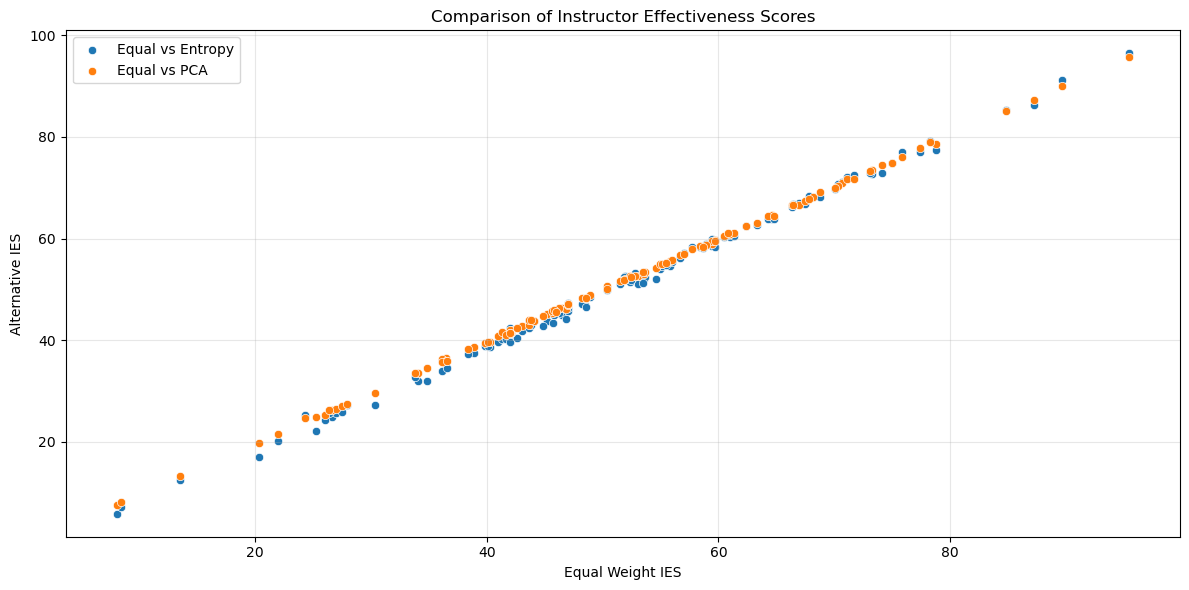

In [100]:
plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=ies_comparison,
    x='IES_Equal',
    y='IES_Entropy',
    label='Equal vs Entropy'
)

sns.scatterplot(
    data=ies_comparison,
    x='IES_Equal',
    y='IES_PCA',
    label='Equal vs PCA'
)

plt.title('Comparison of Instructor Effectiveness Scores')
plt.xlabel('Equal Weight IES')
plt.ylabel('Alternative IES')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [101]:
ies_comparison.to_csv(
    'instructor_ies_comparison.csv',
    index=False
)

print("IES comparison saved successfully.")

IES comparison saved successfully.


In [102]:
# Step 10: Create effectiveness tiers

# Calculate percentile thresholds
low_threshold = ies_comparison['IES_Entropy'].quantile(0.33)
high_threshold = ies_comparison['IES_Entropy'].quantile(0.67)

print("Low threshold:", round(low_threshold, 3))
print("High threshold:", round(high_threshold, 3))

# Assign effectiveness levels
ies_comparison['Effectiveness_Level'] = pd.cut(
    ies_comparison['IES_Entropy'],
    bins=[-np.inf, low_threshold, high_threshold, np.inf],
    labels=['Low', 'Medium', 'High'],
    include_lowest=True
)

# Display results
display(
    ies_comparison[
        ['instructor_id', 'IES_Entropy', 'Effectiveness_Level']
    ].head(15).round(3)
)

Low threshold: 43.043
High threshold: 58.267


,instructor_id,IES_Entropy,Effectiveness_Level
0,I_001,44.977,Medium
1,I_002,68.233,High
2,I_003,71.044,High
3,I_004,40.122,Low
4,I_005,77.436,High
5,I_006,24.826,Low
6,I_007,63.842,High
7,I_008,59.667,High
8,I_009,51.755,Medium
9,I_010,96.454,High


Effectiveness Class Distribution:


,Number of Instructors
Effectiveness_Level,
Low,40
Medium,40
High,40


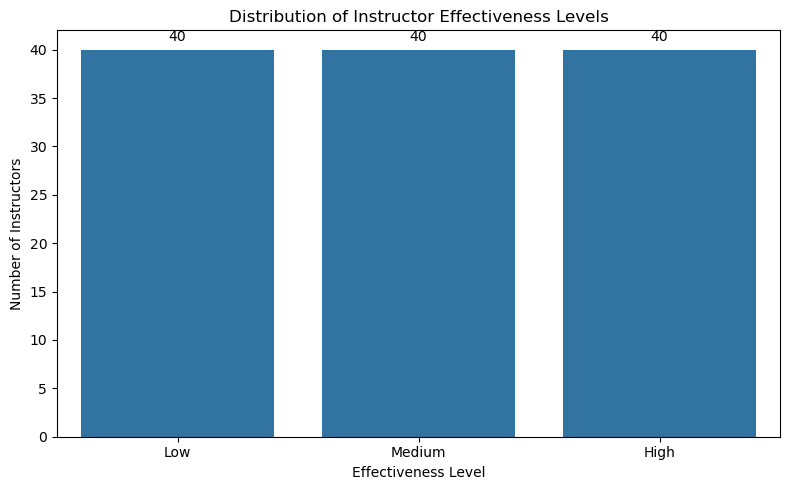

In [103]:
# Count instructors in each effectiveness category

class_distribution = (
    ies_comparison['Effectiveness_Level']
    .value_counts()
    .reindex(['Low', 'Medium', 'High'])
)

print("Effectiveness Class Distribution:")
display(class_distribution.to_frame('Number of Instructors'))

# Visualize distribution
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=class_distribution.index,
    y=class_distribution.values
)

ax.bar_label(ax.containers[0], padding=4)

plt.title('Distribution of Instructor Effectiveness Levels')
plt.xlabel('Effectiveness Level')
plt.ylabel('Number of Instructors')
plt.tight_layout()
plt.show()

In [104]:
class_percentage = (
    class_distribution / len(ies_comparison) * 100
)

print("Class Distribution Percentage:")
display(class_percentage.round(2).to_frame('Percentage'))

Class Distribution Percentage:


,Percentage
Effectiveness_Level,
Low,33.33
Medium,33.33
High,33.33


In [105]:
ies_comparison.to_csv(
    'instructor_effectiveness_labeled.csv',
    index=False
)

print("Labeled instructor dataset saved successfully.")

Labeled instructor dataset saved successfully.


In [141]:
# Create three separate tables based on effectiveness level

high_instructors = ies_comparison[
    ies_comparison['Effectiveness_Level'] == 'High'
].sort_values(by='IES_Entropy', ascending=False).reset_index(drop=True)

medium_instructors = ies_comparison[
    ies_comparison['Effectiveness_Level'] == 'Medium'
].sort_values(by='IES_Entropy', ascending=False).reset_index(drop=True)

low_instructors = ies_comparison[
    ies_comparison['Effectiveness_Level'] == 'Low'
].sort_values(by='IES_Entropy', ascending=False).reset_index(drop=True)


# Display all three tables

print("HIGH EFFECTIVENESS INSTRUCTORS")
display(high_instructors)

print("MEDIUM EFFECTIVENESS INSTRUCTORS")
display(medium_instructors)

print("LOW EFFECTIVENESS INSTRUCTORS")
display(low_instructors)

HIGH EFFECTIVENESS INSTRUCTORS


,instructor_id,IES_Equal,IES_Entropy,IES_PCA,Rank_Equal,Rank_Entropy,Rank_PCA,Effectiveness_Level
0,I_010,95.457508,96.453770,95.799934,1.0,1.0,1.0,High
1,I_037,89.674278,91.138436,90.043086,2.0,2.0,2.0,High
2,I_018,87.217953,86.287310,87.209042,3.0,3.0,3.0,High
3,I_105,84.776636,85.332977,85.022557,4.0,4.0,4.0,High
4,I_118,78.227772,79.212994,78.923001,6.0,5.0,5.0,High
5,I_005,78.761371,77.435528,78.566273,5.0,6.0,6.0,High
6,I_025,75.872092,77.030354,76.100005,8.0,7.0,8.0,High
7,I_091,77.368065,76.983807,77.728170,7.0,8.0,7.0,High
8,I_015,74.992841,74.927525,74.772227,9.0,9.0,9.0,High
9,I_103,73.050851,72.895575,73.223743,12.0,10.0,12.0,High


MEDIUM EFFECTIVENESS INSTRUCTORS


,instructor_id,IES_Equal,IES_Entropy,IES_PCA,Rank_Equal,Rank_Entropy,Rank_PCA,Effectiveness_Level
0,I_096,58.634066,58.144994,58.390587,39.0,41.0,40.0,Medium
1,I_054,57.061258,57.123365,56.889728,42.0,42.0,42.0,Medium
2,I_043,56.676320,56.192020,56.849600,43.0,43.0,43.0,Medium
3,I_097,55.982788,55.400168,55.853721,44.0,44.0,44.0,Medium
4,I_111,55.496040,54.882205,55.162646,46.0,45.0,46.0,Medium
5,I_062,55.101338,54.660480,54.973503,47.0,46.0,47.0,Medium
6,I_040,55.856800,54.558838,55.601232,45.0,47.0,45.0,Medium
7,I_057,54.980417,54.077705,54.888402,48.0,48.0,48.0,Medium
8,I_069,52.833788,53.174775,52.547201,54.0,49.0,55.0,Medium
9,I_071,51.942710,52.709516,52.003746,57.0,50.0,57.0,Medium


LOW EFFECTIVENESS INSTRUCTORS


,instructor_id,IES_Equal,IES_Entropy,IES_PCA,Rank_Equal,Rank_Entropy,Rank_PCA,Effectiveness_Level
0,I_078,43.796914,42.937249,43.947746,81.0,81.0,80.0,Low
1,I_065,44.835698,42.740362,44.659647,79.0,82.0,79.0,Low
2,I_032,43.635390,42.465873,43.016785,83.0,83.0,83.0,Low
3,I_094,42.000494,42.397357,41.920253,89.0,84.0,87.0,Low
4,I_022,43.063270,41.766857,42.785471,84.0,85.0,84.0,Low
5,I_020,42.111155,41.202228,41.971089,87.0,86.0,86.0,Low
6,I_115,42.653810,40.399958,42.338989,85.0,87.0,85.0,Low
7,I_088,41.311007,40.288698,41.646099,92.0,88.0,88.0,Low
8,I_100,41.657087,40.178487,41.089644,91.0,89.0,92.0,Low
9,I_004,42.139717,40.122118,41.381541,86.0,90.0,90.0,Low


### I have also created 3 different tables of 3 effectiveness levels which are high, medium and low with respect to ranking of IES_Entropy

In [144]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Features
X = normalized_df[final_features].copy()

# Target
y = ies_comparison['Effectiveness_Level'].copy()

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: 90
Testing samples: 30

Training class distribution:
Effectiveness_Level
Low       30
Medium    30
High      30
Name: count, dtype: int64

Testing class distribution:
Effectiveness_Level
Low       10
Medium    10
High      10
Name: count, dtype: int64


In [111]:
from xgboost import XGBClassifier

models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ),

    'XGBoost': XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=3,
        eval_metric='mlogloss',
        random_state=42
    )
}

In [113]:
results = []
trained_models = {}

for name, model in models.items():

    if name == 'XGBoost':
        model.fit(
            X_train,
            y_train.cat.codes
        )
        predictions = model.predict(X_test)

        # Convert numeric predictions back to class labels
        predictions = pd.Series(
            predictions
        ).map({
            0: 'Low',
            1: 'Medium',
            2: 'High'
        })

    else:
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, average='weighted'
        ),
        'Recall': recall_score(
            y_test, predictions, average='weighted'
        ),
        'F1 Score': f1_score(
            y_test, predictions, average='weighted'
        )
    })

results_df = pd.DataFrame(results).sort_values(
    by='F1 Score',
    ascending=False
)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
1,Random Forest,0.8333,0.8558,0.8333,0.8359
0,Logistic Regression,0.8333,0.8889,0.8333,0.8325
2,XGBoost,0.8000,0.8139,0.8000,0.8017


In [114]:
# Select the best model based on weighted F1 Score

best_model_name = results_df.sort_values(
    by='F1 Score',
    ascending=False
).iloc[0]['Model']

print("Best model before Optuna tuning:", best_model_name)

Best model before Optuna tuning: Random Forest


In [115]:
!pip install optuna

In [120]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import optuna
import numpy as np

In [121]:
def objective(trial):

    model = RandomForestClassifier(
        n_estimators=trial.suggest_int(
            'n_estimators', 100, 500
        ),
        max_depth=trial.suggest_int(
            'max_depth', 3, 20
        ),
        min_samples_split=trial.suggest_int(
            'min_samples_split', 2, 10
        ),
        min_samples_leaf=trial.suggest_int(
            'min_samples_leaf', 1, 5
        ),
        max_features=trial.suggest_categorical(
            'max_features', ['sqrt', 'log2', None]
        ),
        random_state=42,
        n_jobs=-1
    )

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='f1_weighted',
        n_jobs=-1
    )

    return scores.mean()

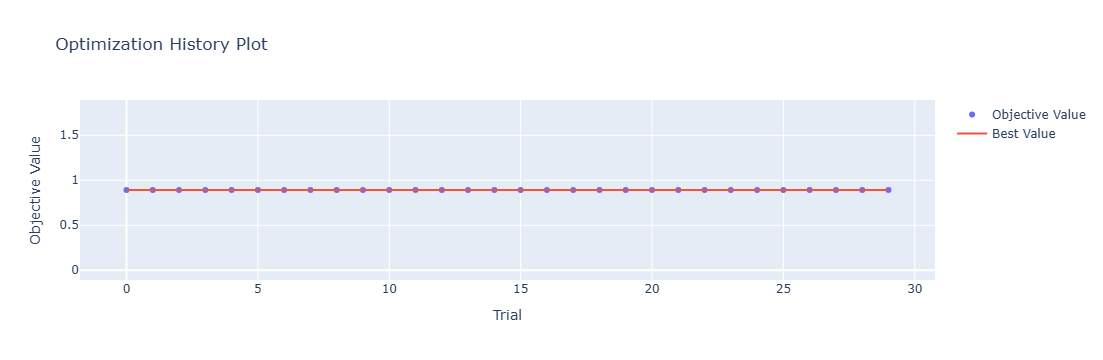

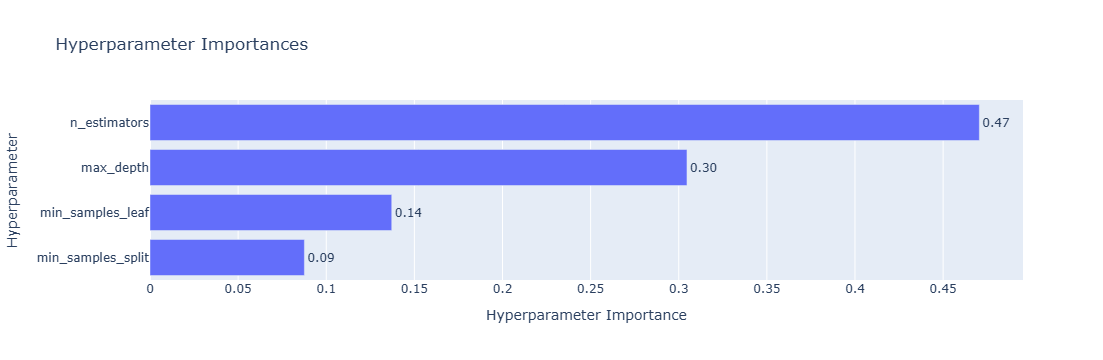

In [122]:
optuna.visualization.plot_optimization_history(study).show()

optuna.visualization.plot_param_importances(study).show()

In [123]:
study = optuna.create_study(
    direction='maximize',
    study_name='Instructor_Effectiveness_Optimization'
)

study.optimize(objective, n_trials=30)

print("Best F1 Score:", study.best_value)
print("\nBest Hyperparameters:")
print(study.best_params)

[I 2026-11-07 21:20:44,081] A new study created in memory with name: Instructor_Effectiveness_Optimization
[I 2026-11-07 21:20:51,635] Trial 0 finished with value: 0.8895770895770896 and parameters: {'n_estimators': 235, 'max_depth': 7, 'min_samples_split': 3, 'min_samples_leaf': 4, 'max_features': 'sqrt'}. Best is trial 0 with value: 0.8895770895770896.
[I 2026-11-07 21:20:59,561] Trial 1 finished with value: 0.9092773892773891 and parameters: {'n_estimators': 159, 'max_depth': 13, 'min_samples_split': 9, 'min_samples_leaf': 3, 'max_features': None}. Best is trial 1 with value: 0.9092773892773891.
[I 2026-11-07 21:21:08,790] Trial 2 finished with value: 0.900921300921301 and parameters: {'n_estimators': 338, 'max_depth': 18, 'min_samples_split': 7, 'min_samples_leaf': 1, 'max_features': 'log2'}. Best is trial 1 with value: 0.9092773892773891.
[I 2026-11-07 21:21:21,719] Trial 3 finished with value: 0.8988988788988788 and parameters: {'n_estimators': 425, 'max_depth': 18, 'min_samples_

Best F1 Score: 0.9105672105672106

Best Hyperparameters:
{'n_estimators': 118, 'max_depth': 11, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_features': None}


In [124]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Baseline Random Forest
baseline_model = trained_models['Random Forest']

# Optimized Random Forest using Optuna
optimized_model = RandomForestClassifier(
    **study.best_params,
    random_state=42,
    n_jobs=-1
)

# Train optimized model on the complete training dataset
optimized_model.fit(X_train, y_train)

# Generate predictions
baseline_predictions = baseline_model.predict(X_test)
optimized_predictions = optimized_model.predict(X_test)

print("Optuna Best Parameters:")
print(study.best_params)

Optuna Best Parameters:
{'n_estimators': 118, 'max_depth': 11, 'min_samples_split': 7, 'min_samples_leaf': 2, 'max_features': None}


In [125]:
evaluation_results = []

model_predictions = {
    'Baseline Random Forest': baseline_predictions,
    'Optimized Random Forest': optimized_predictions
}

for model_name, predictions in model_predictions.items():

    evaluation_results.append({
        'Model': model_name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, predictions, average='weighted', zero_division=0
        )
    })

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline Random Forest,0.8333,0.8558,0.8333,0.8359
1,Optimized Random Forest,0.8000,0.8139,0.8000,0.8017


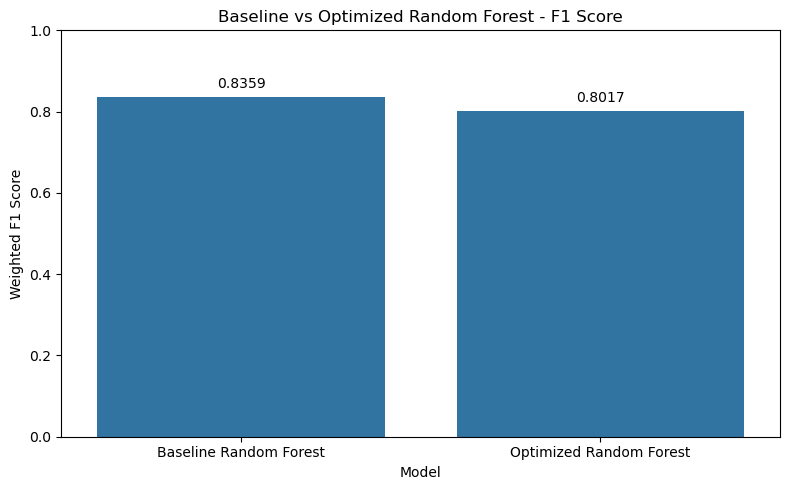

In [126]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=evaluation_df,
    x='Model',
    y='F1 Score'
)

ax.bar_label(ax.containers[0], fmt='%.4f', padding=4)

plt.title('Baseline vs Optimized Random Forest - F1 Score')
plt.ylabel('Weighted F1 Score')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

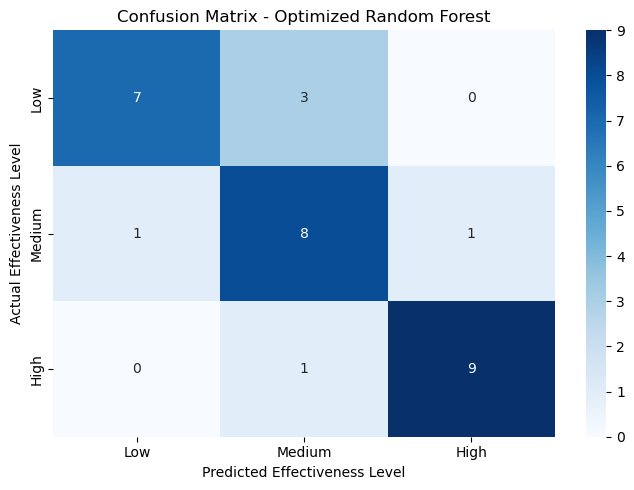

In [127]:
cm = confusion_matrix(
    y_test,
    optimized_predictions,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.title('Confusion Matrix - Optimized Random Forest')
plt.xlabel('Predicted Effectiveness Level')
plt.ylabel('Actual Effectiveness Level')
plt.tight_layout()
plt.show()

In [128]:
print("Classification Report - Optimized Random Forest")

print(
    classification_report(
        y_test,
        optimized_predictions,
        labels=['Low', 'Medium', 'High'],
        zero_division=0
    )
)

Classification Report - Optimized Random Forest
              precision    recall  f1-score   support

         Low       0.88      0.70      0.78        10
      Medium       0.67      0.80      0.73        10
        High       0.90      0.90      0.90        10

    accuracy                           0.80        30
   macro avg       0.81      0.80      0.80        30
weighted avg       0.81      0.80      0.80        30



In [129]:
train_predictions = optimized_model.predict(X_train)

train_f1 = f1_score(
    y_train,
    train_predictions,
    average='weighted'
)

test_f1 = f1_score(
    y_test,
    optimized_predictions,
    average='weighted'
)

print("Training F1 Score:", round(train_f1, 4))
print("Testing F1 Score:", round(test_f1, 4))
print("Cross-validation F1 Score:", round(study.best_value, 4))
print("Train-Test F1 Difference:", round(train_f1 - test_f1, 4))

Training F1 Score: 0.9667
Testing F1 Score: 0.8017
Cross-validation F1 Score: 0.9106
Train-Test F1 Difference: 0.165


In [130]:
# Step 13.1: Random Forest Feature Importance

feature_importance = pd.DataFrame({
    'Feature': final_features,
    'Importance': optimized_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

display(feature_importance.round(4))

,Feature,Importance
7,retention_score,0.5445
6,feedback_response_rate,0.3599
0,avg_score_improvement,0.0324
1,avg_quiz_score,0.0285
2,avg_watch_time,0.0145
5,avg_feedback_score,0.0100
4,forum_activity_rate,0.0078
3,assignment_submission_rate,0.0022


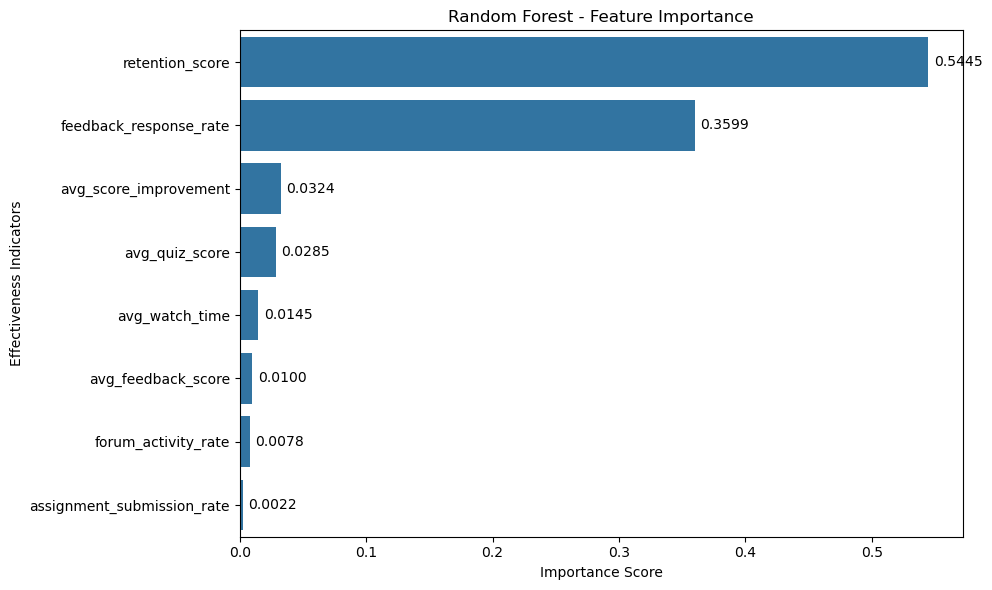

In [131]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=feature_importance,
    x='Importance',
    y='Feature'
)

ax.bar_label(ax.containers[0], fmt='%.4f', padding=4)

plt.title('Random Forest - Feature Importance')
plt.xlabel('Importance Score')
plt.ylabel('Effectiveness Indicators')
plt.tight_layout()
plt.show()

In [132]:
from sklearn.inspection import permutation_importance

permutation_result = permutation_importance(
    optimized_model,
    X_test,
    y_test,
    scoring='f1_weighted',
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

permutation_df = pd.DataFrame({
    'Feature': final_features,
    'Importance': permutation_result.importances_mean,
    'Standard Deviation': permutation_result.importances_std
})

permutation_df = permutation_df.sort_values(
    by='Importance',
    ascending=False
)

display(permutation_df.round(4))

,Feature,Importance,Standard Deviation
7,retention_score,0.2753,0.0785
6,feedback_response_rate,0.1848,0.0655
1,avg_quiz_score,0.0229,0.0126
5,avg_feedback_score,0.0139,0.0149
2,avg_watch_time,0.0099,0.0141
4,forum_activity_rate,0.0090,0.0137
3,assignment_submission_rate,0.0000,0.0000
0,avg_score_improvement,0.0000,0.0000


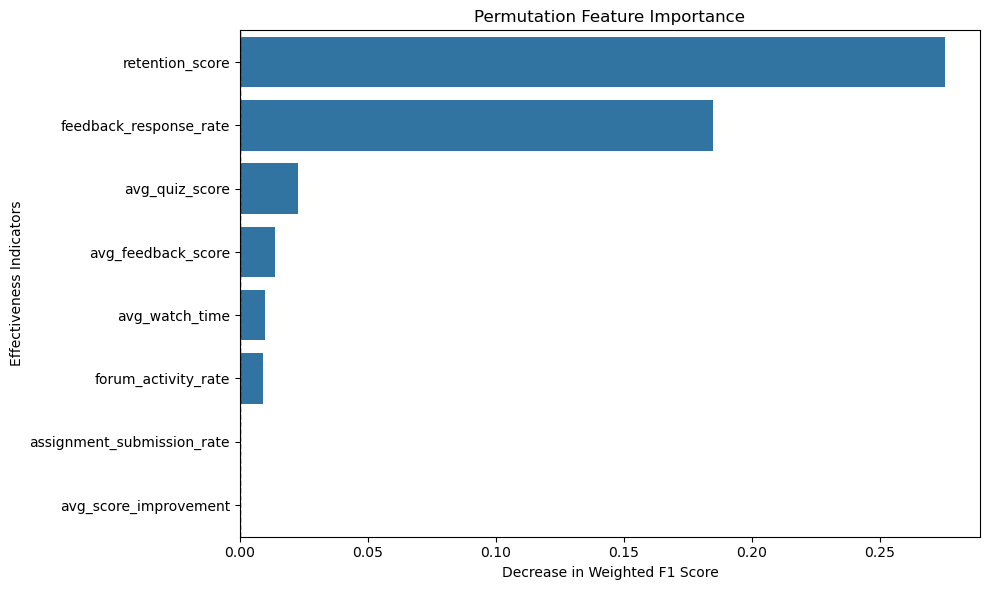

In [133]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=permutation_df,
    x='Importance',
    y='Feature'
)

plt.title('Permutation Feature Importance')
plt.xlabel('Decrease in Weighted F1 Score')
plt.ylabel('Effectiveness Indicators')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

In [134]:
importance_comparison = pd.DataFrame({
    'Feature': final_features,
    'Entropy Weight': entropy_weights.values,
    'PCA Weight': pca_weights.values,
    'RF Importance': optimized_model.feature_importances_,
    'Permutation Importance': permutation_result.importances_mean
})

display(
    importance_comparison
    .sort_values('RF Importance', ascending=False)
    .round(4)
)

,Feature,Entropy Weight,PCA Weight,RF Importance,Permutation Importance
7,retention_score,0.1811,0.1415,0.5445,0.2753
6,feedback_response_rate,0.1561,0.1267,0.3599,0.1848
0,avg_score_improvement,0.1300,0.1317,0.0324,0.0000
1,avg_quiz_score,0.0988,0.1296,0.0285,0.0229
2,avg_watch_time,0.1399,0.1166,0.0145,0.0099
5,avg_feedback_score,0.1319,0.1288,0.0100,0.0139
4,forum_activity_rate,0.0809,0.1159,0.0078,0.0090
3,assignment_submission_rate,0.0813,0.1092,0.0022,0.0000


In [135]:
# Step 14.1: Combine IES scores with instructor workload

final_instructor_analysis = ies_comparison.merge(
    instructor_df[
        ['instructor_id', 'total_batches', 'total_courses']
    ],
    on='instructor_id',
    how='left'
)

final_instructor_analysis = final_instructor_analysis.sort_values(
    by='IES_Entropy',
    ascending=False
).reset_index(drop=True)

final_instructor_analysis['Overall_Rank'] = (
    final_instructor_analysis['IES_Entropy']
    .rank(ascending=False, method='min')
    .astype(int)
)

display(final_instructor_analysis.head())

,instructor_id,IES_Equal,IES_Entropy,IES_PCA,Rank_Equal,Rank_Entropy,Rank_PCA,Effectiveness_Level,total_batches,total_courses,Overall_Rank
0,I_010,95.457508,96.453770,95.799934,1.0,1.0,1.0,High,13,10,1
1,I_037,89.674278,91.138436,90.043086,2.0,2.0,2.0,High,15,12,2
2,I_018,87.217953,86.287310,87.209042,3.0,3.0,3.0,High,14,11,3
3,I_105,84.776636,85.332977,85.022557,4.0,4.0,4.0,High,16,12,4
4,I_118,78.227772,79.212994,78.923001,6.0,5.0,5.0,High,19,14,5


In [136]:
top_10_instructors = final_instructor_analysis.nlargest(
    10, 'IES_Entropy'
)

print("Top 10 Instructors by Effectiveness Score:")

display(
    top_10_instructors[
        [
            'instructor_id',
            'IES_Entropy',
            'Effectiveness_Level',
            'total_batches',
            'total_courses',
            'Overall_Rank'
        ]
    ].round(3)
)

Top 10 Instructors by Effectiveness Score:


,instructor_id,IES_Entropy,Effectiveness_Level,total_batches,total_courses,Overall_Rank
0,I_010,96.454,High,13,10,1
1,I_037,91.138,High,15,12,2
2,I_018,86.287,High,14,11,3
3,I_105,85.333,High,16,12,4
4,I_118,79.213,High,19,14,5
5,I_005,77.436,High,19,13,6
6,I_025,77.030,High,19,14,7
7,I_091,76.984,High,8,7,8
8,I_015,74.928,High,17,11,9
9,I_103,72.896,High,18,14,10


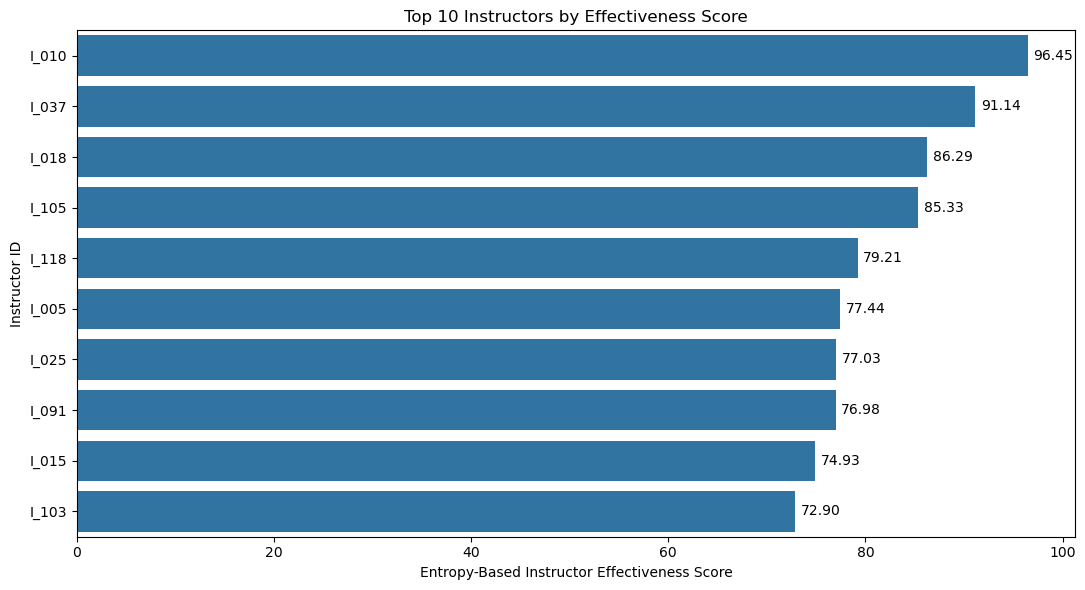

In [137]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=top_10_instructors,
    x='IES_Entropy',
    y='instructor_id'
)

ax.bar_label(ax.containers[0], fmt='%.2f', padding=4)

plt.title('Top 10 Instructors by Effectiveness Score')
plt.xlabel('Entropy-Based Instructor Effectiveness Score')
plt.ylabel('Instructor ID')
plt.tight_layout()
plt.show()

In [138]:
# Calculate Spearman correlations

workload_correlations = final_instructor_analysis[
    ['IES_Entropy', 'total_batches', 'total_courses']
].corr(method='spearman')

print("Workload and Effectiveness Correlations:")

display(workload_correlations.round(4))

Workload and Effectiveness Correlations:


,IES_Entropy,total_batches,total_courses
IES_Entropy,1.0000,0.0814,0.0532
total_batches,0.0814,1.0000,0.8446
total_courses,0.0532,0.8446,1.0000


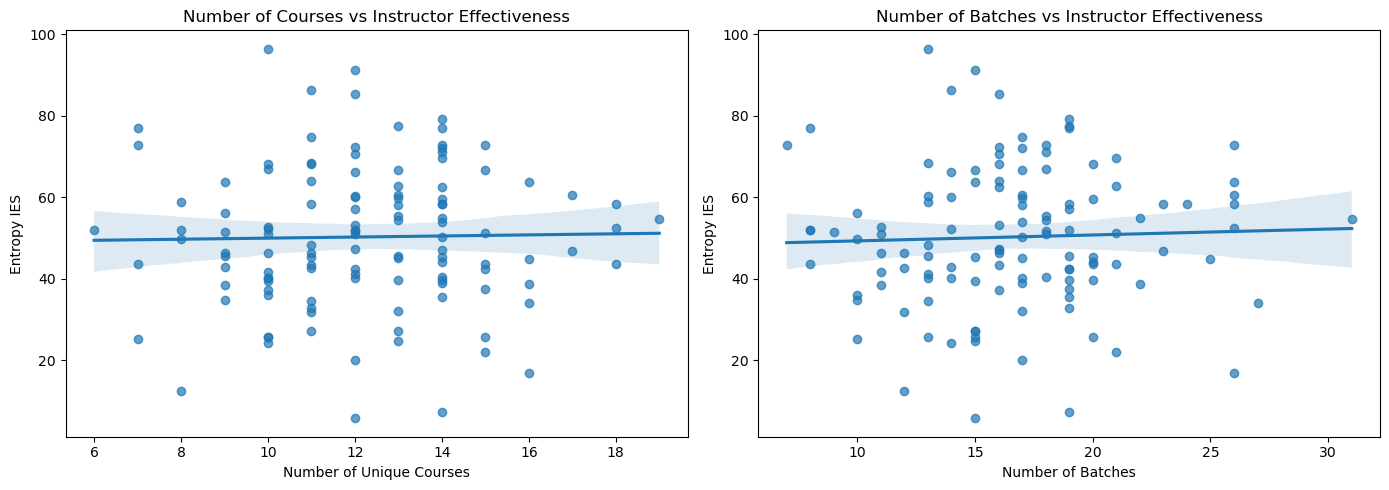

In [139]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=final_instructor_analysis,
    x='total_courses',
    y='IES_Entropy',
    ax=axes[0],
    scatter_kws={'alpha': 0.7}
)

axes[0].set_title('Number of Courses vs Instructor Effectiveness')
axes[0].set_xlabel('Number of Unique Courses')
axes[0].set_ylabel('Entropy IES')

sns.regplot(
    data=final_instructor_analysis,
    x='total_batches',
    y='IES_Entropy',
    ax=axes[1],
    scatter_kws={'alpha': 0.7}
)

axes[1].set_title('Number of Batches vs Instructor Effectiveness')
axes[1].set_xlabel('Number of Batches')
axes[1].set_ylabel('Entropy IES')

plt.tight_layout()
plt.show()

In [140]:
final_instructor_analysis.to_csv(
    'final_instructor_effectiveness_analysis.csv',
    index=False
)

print("Final instructor analysis saved successfully.")

Final instructor analysis saved successfully.


#### 1. Which features most influenced instructor effectiveness, and why? 
#### -> 'Retention score' is the most influenced instructor effectiveness because the completion rate and droupout rate provide information about learner's performance and the result of dropout if a learner won't perform great

#### 2. Which variables could be misleading or confounded?
#### -> 'Average Higher watchtime' because higher watch time does not mean better learning
#### -> 'Assignment submission rate' because assignment submission does not mean a learner have learned every task which were given to him or it miight be possible that the assignement can be done by any other student on behalf of that particular student

#### 3.How could this model fail in real-world usage? 
#### -> Limited dataset, difference between new an old students, differences between course

#### 4.What additional data would you want to improve this analysis?
#### -> i would add student's initial assessment score and final assessment score so we can find out learning outcomes

#### 5.Should this model be used for instructor performance evaluation? Why or why not?
#### -> no, it should not be used for instructor performance evaluation because it's result are based on student's past, limtes data and assumptions